In [ ]:
# CELL 1 - SETUP, UPLOAD DCGAN STAGE 3 REFINED MASKS ZIP
!pip -q install timm scikit-learn pandas matplotlib tqdm pillow

from google.colab import drive, files
from pathlib import Path, PurePosixPath
from concurrent.futures import ThreadPoolExecutor
import os, zipfile, shutil, glob, random, gc, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, auc)
import timm

drive.mount('/content/drive')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type != 'cuda':
    raise RuntimeError('Enable a Colab GPU: Runtime > Change runtime type > GPU.')

ROOT = '/content/drive/MyDrive/DR_Project'
STAGE1_W = ROOT + '/stage1/weights/stage1_original_fixed_best_dr_b0.pth'
SPLIT_DIR = ROOT + '/splits'

# Use your already-extracted RGB image folder in Drive. Nothing is extracted there.
RGB_CANDIDATES = [
    Path('/content/drive/MyDrive/Dataset/colored_images/colored_images'),
    Path('/content/drive/MyDrive/Dataset_extracted/colored_images/colored_images'),
]
RGB_DRIVE_ROOT = next((p for p in RGB_CANDIDATES if p.is_dir()), None)
if RGB_DRIVE_ROOT is None:
    raise FileNotFoundError('Original DR2015 RGB folder missing. Set RGB_CANDIDATES to your Drive folder.')
DRIVE_IMAGE_ROOT = str(RGB_DRIVE_ROOT)
IMAGE_DIR = DRIVE_IMAGE_ROOT

# Save classification results locally, not Google Drive.
OUT_DIR =  '/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE'
CKPT = OUT_DIR + '/stage3_selected_best.pth'
HISTORY = OUT_DIR + '/selected_model_history.csv'
os.makedirs(OUT_DIR, exist_ok=True)

if not Path(STAGE1_W).is_file():
    raise FileNotFoundError('Stage 1 B0 weights missing: ' + STAGE1_W)
if not Path(SPLIT_DIR).is_dir():
    raise FileNotFoundError('Stage 1 splits directory missing: ' + SPLIT_DIR)

# Upload the already-refined DCGAN Stage 3 vessel masks ZIP.
# For a ZIP already in Colab, set STAGE3_ZIP_PATH='/content/your_file.zip'.
STAGE3_ZIP_PATH = None
if STAGE3_ZIP_PATH is None:
    print('Upload stage3_masks.zip (or your complete DR2015_DCGAN_Refined.zip).')
    uploaded = files.upload()
    zip_names = [n for n in uploaded if n.lower().endswith('.zip')]
    if len(zip_names) != 1:
        raise ValueError('Upload exactly one ZIP file containing DCGAN-refined stage3_masks.')
    STAGE3_ZIP_PATH = str(Path('/content') / zip_names[0])
else:
    STAGE3_ZIP_PATH = str(Path(STAGE3_ZIP_PATH))
if not Path(STAGE3_ZIP_PATH).is_file():
    raise FileNotFoundError(STAGE3_ZIP_PATH)

STAGE3_MASK_DIR = Path('/content/dr2015_stage3_dcgan_masks')
STAGE3_MASK_DIR.mkdir(parents=True, exist_ok=True)
CLASS_ALIASES = {
    'no_dr':'No_DR', 'mild':'Mild', 'moderate':'Moderate',
    'severe':'Severe', 'proliferate_dr':'Proliferate_DR',
    'proliferative_dr':'Proliferate_DR'
}
IMAGE_EXTENSIONS = {'.png','.jpg','.jpeg','.tif','.tiff','.bmp'}

# Extract ONLY stage3_masks image files, avoiding huge unnecessary Stage2/NPY data.
# Also supports ZIPs whose root contains the 5 class folders directly.
with zipfile.ZipFile(STAGE3_ZIP_PATH) as archive:
    members=[]
    for member in archive.infolist():
        if member.is_dir(): continue
        parts = PurePosixPath(member.filename).parts
        if '..' in parts or not parts: raise ValueError('Unsafe ZIP entry: ' + member.filename)
        if Path(member.filename).suffix.lower() not in IMAGE_EXTENSIONS: continue
        stage3_indexes=[i for i,x in enumerate(parts[:-1]) if x.lower()=='stage3_masks']
        if stage3_indexes:
            following = parts[stage3_indexes[-1]+1:-1]
        else:
            following = parts[:-1]
        cls = next((CLASS_ALIASES[x.lower()] for x in following if x.lower() in CLASS_ALIASES),None)
        if cls is None: continue
        filename=parts[-1]
        if not Path(filename).stem.lower().endswith('_s3'):
            continue  # Prevent accidentally using original/predicted Stage 2 masks.
        members.append((member,cls,filename))
    if not members:
        raise RuntimeError('ZIP contains no class-wise DCGAN refined *_s3.png masks.')
    print('DCGAN refined masks found in ZIP:',len(members))
    extracted=set()
    for member,cls,filename in tqdm(members,desc='Extracting DCGAN Stage 3 masks',unit='mask'):
        key=(cls,filename.lower())
        if key in extracted: raise ValueError('Duplicate DCGAN mask in ZIP: '+str(key))
        extracted.add(key)
        dst=STAGE3_MASK_DIR/cls/filename
        dst.parent.mkdir(parents=True,exist_ok=True)
        if dst.is_file() and dst.stat().st_size == member.file_size: continue
        temp=dst.with_name(dst.name+'.part')
        with archive.open(member) as f,open(temp,'wb') as w:
            shutil.copyfileobj(f,w,1024*1024)
        temp.replace(dst)

print('RGB source in Drive:',DRIVE_IMAGE_ROOT)
print('Local refined vessel masks:',STAGE3_MASK_DIR)
print('Local output directory:',OUT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Upload stage3_masks.zip (or your complete DR2015_DCGAN_Refined.zip).


Saving stage3_masks.zip to stage3_masks (1).zip
DCGAN refined masks found in ZIP: 35126


Extracting DCGAN Stage 3 masks:   0%|          | 0/35126 [00:00<?, ?mask/s]

RGB source in Drive: /content/drive/MyDrive/Dataset_extracted/colored_images/colored_images
Local refined vessel masks: /content/dr2015_stage3_dcgan_masks
Local output directory: /content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE


In [ ]:
# CELL 2 - CONFIRM DCGAN REFINED MASKS
assert STAGE3_MASK_DIR.is_dir(), 'Run Cell 1 first.'
STAGE3_LOCAL = str(STAGE3_MASK_DIR.parent)
print('DCGAN Stage 3 refined mask root:', STAGE3_MASK_DIR)
print('Classification results will be:', OUT_DIR)


DCGAN Stage 3 refined mask root: /content/dr2015_stage3_dcgan_masks
Classification results will be: /content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE


In [ ]:
import os
import gc
import copy
import shutil
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import timm
import matplotlib.pyplot as plt

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

AMP_DEVICE = (
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Seed fixed: {SEED}")


STAGE3_SIZE = 384
STAGE3_BATCH = 64
STAGE3_NUM_WORKERS = 8

PIN_MEMORY = torch.cuda.is_available()

STAGE3_LOCAL = str(STAGE3_MASK_DIR.parent)

RESULTS_DIR = os.path.join(
    OUT_DIR,
    "results"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

CLASS_NAMES = [
    "no_dr",
    "mild",
    "moderate",
    "severe",
    "proliferative_dr"
]

num_classes = len(CLASS_NAMES)

print(f"Results dir       : {RESULTS_DIR}")
print(f"Classes           : {CLASS_NAMES}")

Device: cuda
Seed fixed: 42
Results dir       : /content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/results
Classes           : ['no_dr', 'mild', 'moderate', 'severe', 'proliferative_dr']


In [ ]:
STAGE1_W = "/content/drive/MyDrive/DR_Project/stage1/weights/stage1_original_fixed_best_dr_b0.pth"



stage1 = timm.create_model(
    "tf_efficientnet_b0.ns_jft_in1k",
    pretrained=False,
    num_classes=num_classes
)

stage1.load_state_dict(torch.load(STAGE1_W, map_location=device))
stage1 = stage1.to(device)
stage1.eval()

for p in stage1.parameters():
    p.requires_grad = False

print("Stage1 loaded")

Stage1 loaded


In [ ]:
# CELL 5 - FAST LOCAL RGB COPY (same 8-worker transfer as original notebook)
import os
import shutil
import time

from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm


DRIVE_IMAGE_ROOT = str(RGB_DRIVE_ROOT)

LOCAL_IMAGE_ROOT = "/content/dr_images"

COPY_COMPLETE_FILE = "/content/.dr_images_dcgan_copy_complete"

MAX_WORKERS = 8
MAX_RETRIES = 5


os.makedirs(
    LOCAL_IMAGE_ROOT,
    exist_ok=True
)


if not os.path.exists(DRIVE_IMAGE_ROOT):
    raise RuntimeError(
        f"Google Drive folder not found:\n{DRIVE_IMAGE_ROOT}"
    )


print("Scanning files...")


all_files = []

for root, dirs, filenames in os.walk(
    DRIVE_IMAGE_ROOT
):

    for filename in filenames:

        src = os.path.join(
            root,
            filename
        )

        relative_path = os.path.relpath(
            src,
            DRIVE_IMAGE_ROOT
        )

        dst = os.path.join(
            LOCAL_IMAGE_ROOT,
            relative_path
        )

        all_files.append(
            (src, dst)
        )


print(
    f"Total files: {len(all_files):,}"
)


remaining_files = []


for src, dst in tqdm(
    all_files,
    desc="Checking existing files",
    unit="file"
):

    try:

        if os.path.exists(dst):

            src_size = os.path.getsize(src)
            dst_size = os.path.getsize(dst)

            if src_size == dst_size:
                continue

            os.remove(dst)

        remaining_files.append(
            (src, dst)
        )

    except Exception:

        remaining_files.append(
            (src, dst)
        )


already_complete = (
    len(all_files)
    -
    len(remaining_files)
)


print(
    f"\nAlready copied correctly: {already_complete:,}"
)

print(
    f"Remaining to copy: {len(remaining_files):,}"
)


def copy_with_retry(item):

    src, dst = item

    os.makedirs(
        os.path.dirname(dst),
        exist_ok=True
    )

    last_error = None


    for attempt in range(
        1,
        MAX_RETRIES + 1
    ):

        try:

            if os.path.exists(dst):

                try:

                    if (
                        os.path.getsize(src)
                        ==
                        os.path.getsize(dst)
                    ):
                        return True, src, None

                except Exception:
                    pass


                try:
                    os.remove(dst)
                except Exception:
                    pass


            shutil.copyfile(
                src,
                dst
            )


            if (
                os.path.getsize(src)
                !=
                os.path.getsize(dst)
            ):

                raise IOError(
                    "Copied file size does not match source."
                )


            return True, src, None


        except Exception as e:

            last_error = e


            try:
                if os.path.exists(dst):
                    os.remove(dst)
            except Exception:
                pass


            time.sleep(
                min(
                    attempt * 2,
                    10
                )
            )


    return (
        False,
        src,
        str(last_error)
    )


errors = []


with ThreadPoolExecutor(
    max_workers=MAX_WORKERS
) as executor:

    futures = [
        executor.submit(
            copy_with_retry,
            item
        )
        for item in remaining_files
    ]


    for future in tqdm(
        as_completed(futures),
        total=len(futures),
        desc="Copying DR images",
        unit="file"
    ):

        success, src, error = (
            future.result()
        )


        if not success:

            errors.append(
                {
                    "file": src,
                    "error": error
                }
            )


print("\n" + "=" * 70)
print("COPY CHECK")
print("=" * 70)


if errors:

    print(
        f"Files still failed after retries: "
        f"{len(errors):,}"
    )

    print("\nFirst few failed files:")

    for item in errors[:10]:

        print(
            item["file"]
        )

        print(
            item["error"]
        )

    print(
        "\nRun this same cell again. "
        "It will skip all successfully copied files "
        "and retry only the remaining files."
    )

else:

    with open(
        COPY_COMPLETE_FILE,
        "w"
    ) as f:

        f.write("complete")


    print(
        "All DR images copied successfully."
    )

    print(
        "Local folder:",
        LOCAL_IMAGE_ROOT
    )

Scanning files...
Total files: 35,126


Checking existing files:   0%|          | 0/35126 [00:00<?, ?file/s]


Already copied correctly: 0
Remaining to copy: 35,126


Copying DR images:   0%|          | 0/35126 [00:00<?, ?file/s]


COPY CHECK
All DR images copied successfully.
Local folder: /content/dr_images


In [ ]:
# CELL 6 - PAIR LOCAL RGB WITH **DCGAN-REFINED STAGE 3 MASKS**
import os
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

LOCAL_IMAGE_ROOT = Path('/content/dr_images')
if not LOCAL_IMAGE_ROOT.is_dir():
    raise FileNotFoundError('Local RGB files missing. Run fast RGB copy cell first.')
if not STAGE3_MASK_DIR.is_dir():
    raise FileNotFoundError('Stage3 DCGAN masks missing. Run upload cell first.')

CLASS_ALIASES = {
    'no_dr':'No_DR', 'mild':'Mild', 'moderate':'Moderate',
    'severe':'Severe', 'proliferate_dr':'Proliferate_DR',
    'proliferative_dr':'Proliferate_DR'
}
CLASS_TO_LABEL = {'No_DR':0,'Mild':1,'Moderate':2,'Severe':3,'Proliferate_DR':4}
IMG_EXTS={'.jpg','.jpeg','.png','.tif','.tiff','.bmp'}

def cls_of_path(path):
    for p in Path(path).parts:
        if p.lower() in CLASS_ALIASES:
            return CLASS_ALIASES[p.lower()]
    return None

def image_id(path):
    stem=Path(path).stem.lower()
    return stem[:-3] if stem.endswith('_s3') else stem

rgb_files = [p for p in LOCAL_IMAGE_ROOT.rglob('*') if p.is_file() and p.suffix.lower() in IMG_EXTS]
mask_files = [p for p in STAGE3_MASK_DIR.rglob('*') if p.is_file() and p.suffix.lower() in IMG_EXTS and p.stem.lower().endswith('_s3')]
print('Local RGB images:',len(rgb_files))
print('Local DCGAN refined masks:',len(mask_files))

rgb_index={}
for p in tqdm(rgb_files,desc='Indexing local RGB',unit='image'):
    cls=cls_of_path(p)
    if cls is None:continue
    k=(cls,image_id(p))
    if k in rgb_index:raise ValueError('Duplicate original RGB: '+str(k))
    rgb_index[k]=p

mask_index={}
for p in tqdm(mask_files,desc='Indexing DCGAN masks',unit='mask'):
    cls=cls_of_path(p)
    if cls is None:raise ValueError('Unknown severity for mask: '+str(p))
    k=(cls,image_id(p))
    if k in mask_index:raise ValueError('Duplicate refined mask: '+str(k))
    mask_index[k]=p

missing_rgb=set(mask_index)-set(rgb_index)
missing_masks=set(rgb_index)-set(mask_index)
print('Refined masks with no RGB:',len(missing_rgb))
print('RGB images with no refined mask:',len(missing_masks))
if missing_rgb:
    print('Examples:',sorted(missing_rgb)[:8])
    raise RuntimeError('Some DCGAN refined masks do not match original RGB images.')
if missing_masks:
    print('Examples:',sorted(missing_masks)[:8])
    raise RuntimeError('Some original RGB images have no DCGAN Stage 3 refined mask. Refusing incomplete dataset.')

rows=[]
for (cls,stem),p in sorted(rgb_index.items()):
    m=mask_index[(cls,stem)]
    rows.append({
        'img_path':str(p),
        'stage3_mask_path':str(m),
        'label':CLASS_TO_LABEL[cls],
        'class_name':cls,
        'image_id':stem,
        'basename':p.name,
    })
df_stage3=pd.DataFrame(rows)
if df_stage3.duplicated(['class_name','image_id']).any():
    raise ValueError('Duplicate image/mask pairs')
if not df_stage3['img_path'].map(os.path.isfile).all():raise RuntimeError('Missing RGB files')
if not df_stage3['stage3_mask_path'].map(os.path.isfile).all():raise RuntimeError('Missing refined mask files')
assert df_stage3['stage3_mask_path'].str.lower().str.contains('stage3_dcgan_masks').all()
assert df_stage3['stage3_mask_path'].str.lower().str.endswith(('_s3.png','_s3.jpg','_s3.jpeg','_s3.tif','_s3.tiff','_s3.bmp')).all()

manifest=Path(OUT_DIR)/'dr2015_dcgan_stage3_classification_manifest.csv'
df_stage3.to_csv(manifest,index=False)
print('Matched original RGB + DCGAN refined mask pairs:',len(df_stage3))
print(df_stage3.class_name.value_counts().to_string())
print('Local manifest:',manifest)
print(df_stage3[['basename','class_name','stage3_mask_path']].head().to_string(index=False))


Local RGB images: 35126
Local DCGAN refined masks: 35126


Indexing local RGB:   0%|          | 0/35126 [00:00<?, ?image/s]

Indexing DCGAN masks:   0%|          | 0/35126 [00:00<?, ?mask/s]

Refined masks with no RGB: 0
RGB images with no refined mask: 0
Matched original RGB + DCGAN refined mask pairs: 35126
class_name
No_DR             25810
Moderate           5292
Mild               2443
Severe              873
Proliferate_DR      708
Local manifest: /content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/dr2015_dcgan_stage3_classification_manifest.csv
       basename class_name                                           stage3_mask_path
 10030_left.png       Mild  /content/dr2015_stage3_dcgan_masks/Mild/10030_left_s3.png
10030_right.png       Mild /content/dr2015_stage3_dcgan_masks/Mild/10030_right_s3.png
 10085_left.png       Mild  /content/dr2015_stage3_dcgan_masks/Mild/10085_left_s3.png
10085_right.png       Mild /content/dr2015_stage3_dcgan_masks/Mild/10085_right_s3.png
10150_right.png       Mild /content/dr2015_stage3_dcgan_masks/Mild/10150_right_s3.png


In [ ]:
SPLIT_DIR = "/content/drive/MyDrive/DR_Project/splits"

def load_names(filename):
    path = os.path.join(
        SPLIT_DIR,
        filename
    )

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    with open(path, "r") as f:
        return set(
            line.strip()
            for line in f
            if line.strip()
        )

stage1_train_names = load_names(
    "stage1_train_names.txt"
)

stage1_val_names = load_names(
    "stage1_val_names.txt"
)

stage1_test_names = load_names(
    "stage1_test_names.txt"
)

df_stage3["basename"] = (
    df_stage3["img_path"]
    .apply(
        lambda p: os.path.basename(str(p))
    )
)

available_names = set(
    df_stage3["basename"].astype(str)
)

missing_train = (
    stage1_train_names
    -
    available_names
)

missing_val = (
    stage1_val_names
    -
    available_names
)

missing_test = (
    stage1_test_names
    -
    available_names
)

if missing_train:
    raise RuntimeError(
        f"{len(missing_train)} Stage1 train images "
        "are missing from Stage3 data."
    )

if missing_val:
    raise RuntimeError(
        f"{len(missing_val)} Stage1 validation images "
        "are missing from Stage3 data."
    )

if missing_test:
    raise RuntimeError(
        f"{len(missing_test)} Stage1 test images "
        "are missing from Stage3 data."
    )

if stage1_train_names & stage1_val_names:
    raise RuntimeError(
        "Stage1 train and validation overlap."
    )

if stage1_train_names & stage1_test_names:
    raise RuntimeError(
        "Stage1 train and test overlap."
    )

if stage1_val_names & stage1_test_names:
    raise RuntimeError(
        "Stage1 validation and test overlap."
    )

train_df = (
    df_stage3[
        df_stage3["basename"].isin(
            stage1_train_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

val_df = (
    df_stage3[
        df_stage3["basename"].isin(
            stage1_val_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

test_df = (
    df_stage3[
        df_stage3["basename"].isin(
            stage1_test_names
        )
    ]
    .copy()
    .reset_index(drop=True)
)

train_names = set(
    train_df["basename"].astype(str)
)

val_names = set(
    val_df["basename"].astype(str)
)

test_names = set(
    test_df["basename"].astype(str)
)

if train_names != stage1_train_names:
    raise RuntimeError(
        "Stage3 train images do not exactly "
        "match Stage1 train images."
    )

if val_names != stage1_val_names:
    raise RuntimeError(
        "Stage3 validation images do not exactly "
        "match Stage1 validation images."
    )

if test_names != stage1_test_names:
    raise RuntimeError(
        "Stage3 test images do not exactly "
        "match Stage1 test images."
    )

assigned_names = (
    train_names
    |
    val_names
    |
    test_names
)

if assigned_names != available_names:
    raise RuntimeError(
        "Stage1 split files do not exactly cover "
        "the available Stage3 dataset."
    )

print("=" * 70)
print("STAGE1 / STAGE3 IDENTICAL SPLIT")
print("=" * 70)

print(
    "Total dataset :",
    len(df_stage3)
)

print(
    "Train         :",
    len(train_df)
)

print(
    "Validation    :",
    len(val_df)
)

print(
    "Test          :",
    len(test_df)
)

print()
print(
    "Train-Val overlap :",
    len(train_names & val_names)
)

print(
    "Train-Test overlap:",
    len(train_names & test_names)
)

print(
    "Val-Test overlap  :",
    len(val_names & test_names)
)

print()
print(
    "Same Stage1/Stage3 train:",
    train_names == stage1_train_names
)

print(
    "Same Stage1/Stage3 val  :",
    val_names == stage1_val_names
)

print(
    "Same Stage1/Stage3 test :",
    test_names == stage1_test_names
)

print()
print("Train class counts:")

train_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_name:<22}: "
        f"{int(train_counts.get(i, 0)):>5}"
    )

print()
print("Validation class counts:")

val_counts = (
    val_df["label"]
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_name:<22}: "
        f"{int(val_counts.get(i, 0)):>5}"
    )

print()
print("Test class counts:")

test_counts = (
    test_df["label"]
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_name:<22}: "
        f"{int(test_counts.get(i, 0)):>5}"
    )

STAGE1 / STAGE3 IDENTICAL SPLIT
Total dataset : 35126
Train         : 24588
Validation    : 5269
Test          : 5269

Train-Val overlap : 0
Train-Test overlap: 0
Val-Test overlap  : 0

Same Stage1/Stage3 train: True
Same Stage1/Stage3 val  : True
Same Stage1/Stage3 test : True

Train class counts:
no_dr                 : 18067
mild                  :  1710
moderate              :  3704
severe                :   611
proliferative_dr      :   496

Validation class counts:
no_dr                 :  3871
mild                  :   367
moderate              :   794
severe                :   131
proliferative_dr      :   106

Test class counts:
no_dr                 :  3872
mild                  :   366
moderate              :   794
severe                :   131
proliferative_dr      :   106


In [ ]:
# DATASET + DATALOADERS

import random as _random
import torchvision.transforms.functional as TF


_MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
)

_STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
)


class DRStage3Dataset(Dataset):

    def __init__(
        self,
        df,
        size=384,
        augment=False
    ):
        self.df = df.reset_index(drop=True)
        self.size = size
        self.augment = augment


    def __len__(self):
        return len(self.df)


    def _load_rgb(self, path):

        img = Image.open(path).convert("RGB")

        img = img.resize(
            (self.size, self.size),
            Image.BILINEAR
        )

        return img


    def _load_mask(self, path):

        mask = Image.open(path).convert("L")

        mask = mask.resize(
            (self.size, self.size),
            Image.NEAREST
        )

        return mask


    def _augment(
        self,
        img_pil,
        mask_pil
    ):

        # Horizontal flip
        if _random.random() > 0.5:

            img_pil = TF.hflip(img_pil)

            mask_pil = TF.hflip(mask_pil)


        # Vertical flip
        if _random.random() > 0.5:

            img_pil = TF.vflip(img_pil)

            mask_pil = TF.vflip(mask_pil)


        # Rotation
        k = _random.randint(0, 3)

        if k > 0:

            img_pil = TF.rotate(
                img_pil,
                k * 90
            )

            mask_pil = TF.rotate(
                mask_pil,
                k * 90
            )


        # Brightness
        if _random.random() > 0.4:

            img_pil = TF.adjust_brightness(
                img_pil,
                1.0 + _random.uniform(-0.3, 0.3)
            )


        # Contrast
        if _random.random() > 0.4:

            img_pil = TF.adjust_contrast(
                img_pil,
                1.0 + _random.uniform(-0.3, 0.3)
            )


        # Saturation
        if _random.random() > 0.4:

            img_pil = TF.adjust_saturation(
                img_pil,
                1.0 + _random.uniform(-0.3, 0.3)
            )


        return img_pil, mask_pil


    def _to_tensor(
        self,
        img_pil,
        mask_pil
    ):

        # RGB image
        arr = (
            np.array(img_pil)
            .astype(np.float32)
            / 255.0
        )

        arr = (
            arr - _MEAN
        ) / _STD


        rgb = torch.tensor(
            np.transpose(
                arr,
                (2, 0, 1)
            ),
            dtype=torch.float32
        )


        # Stage 3 mask
        m = (
            np.array(mask_pil)
            .astype(np.float32)
            / 255.0
            > 0.5
        ).astype(np.float32)


        mask = torch.tensor(
            m[None, :, :],
            dtype=torch.float32
        )


        return rgb, mask


    def __getitem__(self, idx):

        row = self.df.iloc[idx]


        # Original RGB image
        img_pil = self._load_rgb(
            str(row["img_path"])
        )


        # STRICTLY STAGE 3 MASK
        mask_pil = self._load_mask(
            str(row["stage3_mask_path"])
        )


        label = int(
            row["label"]
        )


        if self.augment:

            img_pil, mask_pil = self._augment(
                img_pil,
                mask_pil
            )


        rgb, mask = self._to_tensor(
            img_pil,
            mask_pil
        )


        return rgb, mask, label


# --------------------------------------------------
# OVERSAMPLING
# --------------------------------------------------

# Mild 2x, severe 2x, PDR 2x
mild_df = train_df[
    train_df["label"] == 1
]

severe_df = train_df[
    train_df["label"] == 3
]

pdr_df = train_df[
    train_df["label"] == 4
]


train_df_balanced = pd.concat(
    [
        train_df,
        mild_df,
        severe_df,
        pdr_df,
    ],
    ignore_index=True
)


print(
    "Balanced train class counts:"
)

vc = (
    train_df_balanced["label"]
    .value_counts()
    .sort_index()
)


for i, cn in enumerate(CLASS_NAMES):

    n = vc.get(i, 0)

    print(
        f"  {cn:<22}: {n:>5}"
    )


print(
    f"\nTrain original : "
    f"{len(train_df)}"
)

print(
    f"Train balanced : "
    f"{len(train_df_balanced)}"
)

print(
    f"Val            : "
    f"{len(val_df)}"
)

print(
    f"Test           : "
    f"{len(test_df)}"
)


# --------------------------------------------------
# DATASETS
# --------------------------------------------------

stage3_train_ds = DRStage3Dataset(
    train_df_balanced,
    size=STAGE3_SIZE,
    augment=True
)

stage3_val_ds = DRStage3Dataset(
    val_df,
    size=STAGE3_SIZE,
    augment=False
)

stage3_test_ds = DRStage3Dataset(
    test_df,
    size=STAGE3_SIZE,
    augment=False
)


# --------------------------------------------------
# DATALOADERS
# --------------------------------------------------

dr_train_loader = DataLoader(
    stage3_train_ds,
    batch_size=STAGE3_BATCH,
    shuffle=True,
    num_workers=STAGE3_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True,
    prefetch_factor=2
)


dr_val_loader = DataLoader(
    stage3_val_ds,
    batch_size=STAGE3_BATCH,
    shuffle=False,
    num_workers=STAGE3_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True,
    prefetch_factor=2
)


dr_test_loader = DataLoader(
    stage3_test_ds,
    batch_size=STAGE3_BATCH,
    shuffle=False,
    num_workers=STAGE3_NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=True,
    prefetch_factor=2
)


print(
    f"\nTrain batches  : "
    f"{len(dr_train_loader)}"
)

print(
    f"Val batches    : "
    f"{len(dr_val_loader)}"
)

print(
    f"Test batches   : "
    f"{len(dr_test_loader)}"
)

Balanced train class counts:
  no_dr                 : 18067
  mild                  :  3420
  moderate              :  3704
  severe                :  1222
  proliferative_dr      :   992

Train original : 24588
Train balanced : 27405
Val            : 5269
Test           : 5269

Train batches  : 429
Val batches    : 83
Test batches   : 83


In [ ]:
import numpy as np

import torch
import torch.nn as nn

import timm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize


RGB_SCALE = 0.75
MASK_SCALE = 1.25
DROP = 0.45


if "AMP_DEVICE" not in globals():

    AMP_DEVICE = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )


def macro_auc(
    y_true,
    probabilities
):

    try:

        y_binary = label_binarize(
            y_true,
            classes=list(
                range(
                    num_classes
                )
            )
        )

        return roc_auc_score(
            y_binary,
            probabilities,
            average="macro",
            multi_class="ovr"
        )

    except Exception:

        return np.nan


class SEBlock(nn.Module):

    def __init__(
        self,
        in_dim,
        reduction=16
    ):

        super().__init__()

        hidden_dim = max(
            1,
            in_dim // reduction
        )

        self.fc = nn.Sequential(

            nn.Linear(
                in_dim,
                hidden_dim,
                bias=False
            ),

            nn.ReLU(
                inplace=True
            ),

            nn.Linear(
                hidden_dim,
                in_dim,
                bias=False
            ),

            nn.Sigmoid()
        )


    def forward(
        self,
        x
    ):

        weights = self.fc(
            x
        )

        return (
            x
            *
            weights
        )


class _MaskEncoderProxy:

    def __init__(
        self,
        model
    ):

        self.enc3 = (
            model.blocks[-2]
        )

        self.enc4 = (
            model.blocks[-1]
        )


class Stage3EfficientNetB0BxSE(nn.Module):

    def __init__(
        self,
        num_classes,
        stage1_weight_path,
        mask_model_name,
        mask_pretrained=True
    ):

        super().__init__()


        self.rgb_scale = (
            RGB_SCALE
        )

        self.mask_scale = (
            MASK_SCALE
        )

        self.mask_model_name = (
            mask_model_name
        )


        rgb_model = timm.create_model(
            "tf_efficientnet_b0.ns_jft_in1k",
            pretrained=False,
            num_classes=0,
            global_pool="avg"
        )


        stage1_state = torch.load(
            stage1_weight_path,
            map_location="cpu"
        )


        if (
            isinstance(
                stage1_state,
                dict
            )
            and
            "state_dict"
            in stage1_state
        ):

            stage1_state = (
                stage1_state[
                    "state_dict"
                ]
            )


        if (
            isinstance(
                stage1_state,
                dict
            )
            and
            "model_state_dict"
            in stage1_state
        ):

            stage1_state = (
                stage1_state[
                    "model_state_dict"
                ]
            )


        stage1_state = {

            key:
                value

            for (
                key,
                value
            )
            in stage1_state.items()

            if not key.startswith(
                "classifier"
            )
        }


        rgb_model.load_state_dict(
            stage1_state,
            strict=False
        )


        for parameter in (
            rgb_model.parameters()
        ):

            parameter.requires_grad = False


        self.rgb_branch = (
            rgb_model
        )


        mask_model = timm.create_model(
            mask_model_name,
            pretrained=mask_pretrained,
            num_classes=0,
            global_pool="avg"
        )


        old_conv = (
            mask_model.conv_stem
        )


        new_conv = nn.Conv2d(
            1,
            old_conv.out_channels,
            kernel_size=
                old_conv.kernel_size,
            stride=
                old_conv.stride,
            padding=
                old_conv.padding,
            dilation=
                old_conv.dilation,
            groups=
                old_conv.groups,
            bias=False
        )


        with torch.no_grad():

            new_conv.weight.copy_(
                old_conv.weight.mean(
                    dim=1,
                    keepdim=True
                )
            )


        mask_model.conv_stem = (
            new_conv
        )


        if hasattr(
            mask_model,
            "set_grad_checkpointing"
        ):

            try:

                mask_model.set_grad_checkpointing(
                    True
                )

            except Exception:

                pass


        self.mask_branch = (
            mask_model
        )


        self._mask_encoder_proxy = (
            _MaskEncoderProxy(
                mask_model
            )
        )


        self.RGB_DIM = int(
            rgb_model.num_features
        )


        self.MASK_DIM = int(
            mask_model.num_features
        )


        self.FUSE_DIM = (
            self.RGB_DIM
            +
            self.MASK_DIM
        )


        self.se = SEBlock(
            self.FUSE_DIM,
            reduction=16
        )


        self.head = nn.Sequential(

            nn.Dropout(
                DROP
            ),

            nn.Linear(
                self.FUSE_DIM,
                num_classes
            )
        )


    @property
    def mask_encoder(
        self
    ):

        return (
            self._mask_encoder_proxy
        )


    def _features(
        self,
        rgb,
        mask
    ):

        with torch.no_grad():

            rgb_features = (
                self.rgb_branch(
                    rgb
                )
            )

        mask_features = (
            self.mask_branch(
                mask
            )
        )


        rgb_features = (
            self.rgb_scale
            *
            rgb_features
        )


        mask_features = (
            self.mask_scale
            *
            mask_features
        )


        fused_features = torch.cat(
            [
                rgb_features,
                mask_features
            ],
            dim=1
        )


        attended_features = (
            self.se(
                fused_features
            )
        )


        return (
            attended_features,
            rgb_features,
            mask_features
        )


    def forward(
        self,
        rgb,
        mask
    ):

        (
            attended_features,
            _,
            _
        ) = self._features(
            rgb,
            mask
        )


        logits = self.head(
            attended_features
        )


        return logits


    def forward_with_parts(
        self,
        rgb,
        mask
    ):

        (
            attended_features,
            rgb_features,
            mask_features
        ) = self._features(
            rgb,
            mask
        )


        logits = self.head(
            attended_features
        )


        return (
            logits,
            mask_features
        )


    def forward_rgb_only(
        self,
        rgb,
        mask=None
    ):

        with torch.no_grad():

            rgb_features = (
                self.rgb_scale
                *
                self.rgb_branch(
                    rgb
                )
            )


        zero_mask_features = (
            torch.zeros(
                rgb_features.size(0),
                self.MASK_DIM,
                device=
                    rgb_features.device,
                dtype=
                    rgb_features.dtype
            )
        )


        fused = torch.cat(
            [
                rgb_features,
                zero_mask_features
            ],
            dim=1
        )


        attended = self.se(
            fused
        )


        return self.head(
            attended
        )


    def forward_mask_only(
        self,
        rgb,
        mask
    ):

        mask_features = (
            self.mask_scale
            *
            self.mask_branch(
                mask
            )
        )


        zero_rgb_features = (
            torch.zeros(
                mask_features.size(0),
                self.RGB_DIM,
                device=
                    mask_features.device,
                dtype=
                    mask_features.dtype
            )
        )


        fused = torch.cat(
            [
                zero_rgb_features,
                mask_features
            ],
            dim=1
        )


        attended = self.se(
            fused
        )


        return self.head(
            attended
        )


@torch.no_grad()
def evaluate(
    model,
    loader
):

    model.eval()


    labels_all = []

    predictions_all = []

    probabilities_all = []

    validation_losses = []


    for (
        rgb,
        mask,
        labels
    ) in loader:


        rgb = rgb.to(
            device,
            non_blocking=True
        )


        mask = mask.to(
            device,
            non_blocking=True
        )


        labels = labels.to(
            device,
            non_blocking=True
        )


        if torch.cuda.is_available():

            rgb = rgb.contiguous(
                memory_format=
                    torch.channels_last
            )


            mask = mask.contiguous(
                memory_format=
                    torch.channels_last
            )


        with torch.amp.autocast(
            device_type=
                AMP_DEVICE,
            enabled=
                torch.cuda.is_available()
        ):

            logits = model(
                rgb,
                mask
            )


            loss = criterion(
                logits,
                labels
            )


            probabilities = (
                torch.softmax(
                    logits,
                    dim=1
                )
            )


        validation_losses.append(
            float(
                loss
                .detach()
                .cpu()
                .item()
            )
        )


        labels_all.extend(
            labels
            .detach()
            .cpu()
            .numpy()
        )


        predictions_all.extend(
            logits
            .argmax(
                dim=1
            )
            .detach()
            .cpu()
            .numpy()
        )


        probabilities_all.extend(
            probabilities
            .detach()
            .cpu()
            .numpy()
        )


    labels_all = np.asarray(
        labels_all
    )


    predictions_all = np.asarray(
        predictions_all
    )


    probabilities_all = np.asarray(
        probabilities_all
    )


    accuracy = accuracy_score(
        labels_all,
        predictions_all
    )


    macro_f1 = f1_score(
        labels_all,
        predictions_all,
        average="macro",
        zero_division=0
    )


    weighted_f1 = f1_score(
        labels_all,
        predictions_all,
        average="weighted",
        zero_division=0
    )


    auc_value = macro_auc(
        labels_all,
        probabilities_all
    )


    recalls = recall_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(
                num_classes
            )
        ),
        zero_division=0
    )


    precisions = precision_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(
                num_classes
            )
        ),
        zero_division=0
    )


    return {

        "labels":
            labels_all,

        "preds":
            predictions_all,

        "probs":
            probabilities_all,

        "loss":
            float(
                np.mean(
                    validation_losses
                )
            ),

        "accuracy":
            accuracy,

        "macro_f1":
            macro_f1,

        "weighted_f1":
            weighted_f1,

        "macro_auc":
            auc_value,

        "recall":
            recalls,

        "precision":
            precisions
    }


print(
    "Stage3EfficientNetB0BxSE defined:",
    "Stage3EfficientNetB0BxSE"
    in globals()
)


print(
    "evaluate defined:",
    "evaluate"
    in globals()
)

Stage3EfficientNetB0BxSE defined: True
evaluate defined: True


In [ ]:
# CELL 10 - TRAIN B0+B3+SE AND B0+B4+SE WITH THE SAME DCGAN STAGE3 MASKS
import os
import gc
import math
import random
import shutil
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
import timm

from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize
from tqdm.auto import tqdm

warnings.filterwarnings(
    "ignore",
    message="name."
)

try:
    from huggingface_hub import logging as hf_logging
    hf_logging.set_verbosity_error()
except Exception:
    pass

EPOCHS = 60
PATIENCE = 5
EFFECTIVE_BATCH = 64

LR = 1e-4
WEIGHT_DECAY = 1e-3

AUX_WEIGHT = 0.40
MASK_DROP_P = 0.10

SEED_COMPARE = 42

MODELS = {
    "B3": "tf_efficientnet_b3.ns_jft_in1k",
    "B4": "tf_efficientnet_b4.ns_jft_in1k"
}

BATCH_BY_MODEL = {
    "B3": 8,
    "B4": 8
}

if "FAST_NUM_WORKERS" not in globals():
    cpu_count = os.cpu_count() or 2
    FAST_NUM_WORKERS = min(
        4,
        max(
            2,
            cpu_count - 1
        )
    )

if "FAST_PIN_MEMORY" not in globals():
    FAST_PIN_MEMORY = torch.cuda.is_available()

if "USE_AMP" not in globals():
    USE_AMP = torch.cuda.is_available()

if "AMP_DEVICE" not in globals():
    AMP_DEVICE = (
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

required_items = [
    "stage3_train_ds",
    "stage3_val_ds",
    "Stage3EfficientNetB0BxSE",
    "device",
    "num_classes",
    "CLASS_NAMES",
    "STAGE1_W"
]

missing = [
    name
    for name in required_items
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required variables: "
        + ", ".join(missing)
        + "\nRun your dataset/model setup cells first."
    )

def seed_all_compare():
    random.seed(SEED_COMPARE)
    np.random.seed(SEED_COMPARE)
    torch.manual_seed(SEED_COMPARE)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED_COMPARE)

DRIVE_COMPARE_DIR = OUT_DIR

LOCAL_COMPARE_DIR = "/content/stage3_dcgan_B3_B4_local"

os.makedirs(
    DRIVE_COMPARE_DIR,
    exist_ok=True
)

os.makedirs(
    LOCAL_COMPARE_DIR,
    exist_ok=True
)

print("Drive comparison directory:")
print(DRIVE_COMPARE_DIR)

LOCAL_STAGE1_W = os.path.join(
    "/content",
    os.path.basename(STAGE1_W)
)

if not os.path.exists(LOCAL_STAGE1_W):
    shutil.copy2(
        STAGE1_W,
        LOCAL_STAGE1_W
    )

class_weights = torch.tensor(
    [
        0.65,
        2.20,
        1.15,
        2.20,
        1.80
    ],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

aux_criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

def macro_auc_with_loss(
    y_true,
    probabilities
):
    try:
        y_binary = label_binarize(
            y_true,
            classes=list(
                range(num_classes)
            )
        )

        return float(
            roc_auc_score(
                y_binary,
                probabilities,
                average="macro",
                multi_class="ovr"
            )
        )

    except Exception:
        return float("nan")

@torch.no_grad()
def evaluate_with_loss(
    model,
    loader
):
    model.eval()

    labels_all = []
    predictions_all = []
    probabilities_all = []
    validation_losses = []

    for rgb, mask, labels in loader:
        rgb = rgb.to(
            device,
            non_blocking=True
        )

        mask = mask.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if torch.cuda.is_available():
            rgb = rgb.contiguous(
                memory_format=torch.channels_last
            )

            mask = mask.contiguous(
                memory_format=torch.channels_last
            )

        with torch.amp.autocast(
            device_type=AMP_DEVICE,
            enabled=USE_AMP
        ):
            logits = model(
                rgb,
                mask
            )

            loss = criterion(
                logits,
                labels
            )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = logits.argmax(
            dim=1
        )

        validation_losses.append(
            float(
                loss.detach()
                .cpu()
                .item()
            )
        )

        labels_all.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        predictions_all.extend(
            predictions.detach()
            .cpu()
            .numpy()
        )

        probabilities_all.extend(
            probabilities.detach()
            .cpu()
            .numpy()
        )

    labels_all = np.asarray(
        labels_all
    )

    predictions_all = np.asarray(
        predictions_all
    )

    probabilities_all = np.asarray(
        probabilities_all
    )

    accuracy = accuracy_score(
        labels_all,
        predictions_all
    )

    macro_f1_value = f1_score(
        labels_all,
        predictions_all,
        average="macro",
        zero_division=0
    )

    weighted_f1_value = f1_score(
        labels_all,
        predictions_all,
        average="weighted",
        zero_division=0
    )

    macro_auc_value = macro_auc_with_loss(
        labels_all,
        probabilities_all
    )

    recalls = recall_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(num_classes)
        ),
        zero_division=0
    )

    precisions = precision_score(
        labels_all,
        predictions_all,
        average=None,
        labels=list(
            range(num_classes)
        ),
        zero_division=0
    )

    return {
        "labels": labels_all,
        "preds": predictions_all,
        "probs": probabilities_all,
        "loss": float(
            np.mean(
                validation_losses
            )
        ),
        "accuracy": float(accuracy),
        "macro_f1": float(macro_f1_value),
        "weighted_f1": float(weighted_f1_value),
        "macro_auc": float(macro_auc_value),
        "recall": recalls,
        "precision": precisions
    }

def make_train_val_loaders(
    batch_size
):
    common = {
        "num_workers": FAST_NUM_WORKERS,
        "pin_memory": FAST_PIN_MEMORY
    }

    if FAST_NUM_WORKERS > 0:
        common[
            "persistent_workers"
        ] = True

        common[
            "prefetch_factor"
        ] = 4

    generator = torch.Generator()

    generator.manual_seed(
        SEED_COMPARE
    )

    train_loader = DataLoader(
        stage3_train_ds,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        **common
    )

    val_loader = DataLoader(
        stage3_val_ds,
        batch_size=batch_size,
        shuffle=False,
        **common
    )

    return (
        train_loader,
        val_loader
    )

def print_saved_training_history(
    short_name
):
    history_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    if not os.path.exists(
        history_path
    ):
        print(
            f"History not found for {short_name}."
        )

        return

    history_df = pd.read_csv(
        history_path
    )

    if len(history_df) == 0:
        print(
            f"History empty for {short_name}."
        )

        return

    print(
        "\n"
        + "=" * 90
    )

    print(
        f"SAVED TRAINING HISTORY: {short_name}"
    )

    print(
        "=" * 90
    )

    best_f1 = -1.0
    wait = 0

    for _, row in history_df.iterrows():
        epoch = int(
            row[
                "epoch"
            ]
        )

        val_f1 = float(
            row[
                "val_macro_f1"
            ]
        )

        print(
            f"{short_name} | "
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train Total Loss={float(row['train_loss']):.4f} | "
            f"Train Main Loss={float(row['train_main_loss']):.4f} | "
            f"Val Loss={float(row['val_loss']):.4f} | "
            f"Val Accuracy={float(row['val_accuracy']):.4f} | "
            f"Val Macro-F1={val_f1:.4f} | "
            f"Val AUROC={float(row['val_macro_auc']):.4f}"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            wait = 0

            print(
                "Best validation Macro-F1 checkpoint saved."
            )

        else:
            wait += 1

            print(
                f"Early stopping patience: "
                f"{wait}/{PATIENCE}"
            )

            if wait >= PATIENCE:
                print(
                    f"{short_name}: Early stopping."
                )

                break

def history_completed(
    short_name
):
    history_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    if not os.path.exists(
        history_path
    ):
        return False

    try:
        history_df = pd.read_csv(
            history_path
        )

        if len(history_df) == 0:
            return False

        required_history_columns = {
            "train_main_loss",
            "val_loss"
        }

        if not required_history_columns.issubset(
            history_df.columns
        ):
            return False

        best_f1 = -1.0
        wait = 0

        for _, row in history_df.iterrows():
            current_f1 = float(
                row[
                    "val_macro_f1"
                ]
            )

            if current_f1 > best_f1:
                best_f1 = current_f1
                wait = 0

            else:
                wait += 1

            if wait >= PATIENCE:
                return True

        last_epoch = int(
            history_df.iloc[-1][
                "epoch"
            ]
        )

        if last_epoch >= EPOCHS:
            return True

        return False

    except Exception:
        return False

def train_one_model(
    short_name,
    timm_model_name
):
    seed_all_compare()

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    batch_size = BATCH_BY_MODEL[
        short_name
    ]

    accumulation_steps = max(
        1,
        math.ceil(
            EFFECTIVE_BATCH
            /
            batch_size
        )
    )

    train_loader, val_loader = (
        make_train_val_loaders(
            batch_size
        )
    )

    model = Stage3EfficientNetB0BxSE(
        num_classes,
        LOCAL_STAGE1_W,
        timm_model_name,
        mask_pretrained=True
    ).to(
        device
    )

    if torch.cuda.is_available():
        model = model.to(
            memory_format=torch.channels_last
        )

    aux_head = nn.Linear(
        model.MASK_DIM,
        num_classes
    ).to(
        device
    )

    optimizer = optim.AdamW(
        [
            {
                "params":
                    model.mask_branch.parameters(),
                "lr":
                    LR
            },
            {
                "params":
                    model.se.parameters(),
                "lr":
                    LR
            },
            {
                "params":
                    model.head.parameters(),
                "lr":
                    LR
            },
            {
                "params":
                    aux_head.parameters(),
                "lr":
                    LR
            }
        ],
        weight_decay=WEIGHT_DECAY
    )

    scheduler = (
        optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=EPOCHS,
            eta_min=1e-7
        )
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )

    drive_checkpoint = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_best.pth"
    )

    drive_history = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    complete_marker = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_COMPLETE.txt"
    )

    best_val_macro_f1 = -1.0
    best_epoch = -1
    wait = 0
    history = []

    print(
        "\n"
        + "=" * 90
    )

    print(
        f"MODEL: {short_name}\n"
        f"EfficientNet: {timm_model_name}\n"
        f"Epochs: {EPOCHS}\n"
        f"Patience: {PATIENCE}"
    )

    print(
        "=" * 90
    )

    for epoch in range(
        1,
        EPOCHS + 1
    ):
        model.train()
        model.rgb_branch.eval()
        aux_head.train()

        optimizer.zero_grad(
            set_to_none=True
        )

        train_losses = []
        train_main_losses = []
        train_labels = []
        train_predictions = []

        train_pbar = tqdm(
            train_loader,
            total=len(
                train_loader
            ),
            desc=(
                f"{short_name} "
                f"Epoch {epoch:02d}/{EPOCHS}"
            ),
            unit="batch",
            dynamic_ncols=True,
            leave=True
        )

        for step, (
            rgb,
            mask,
            labels
        ) in enumerate(
            train_pbar,
            start=1
        ):
            rgb = rgb.to(
                device,
                non_blocking=True
            )

            mask = mask.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            if torch.cuda.is_available():
                rgb = rgb.contiguous(
                    memory_format=torch.channels_last
                )

                mask = mask.contiguous(
                    memory_format=torch.channels_last
                )

            if MASK_DROP_P > 0:
                keep = (
                    torch.rand(
                        mask.size(0),
                        1,
                        1,
                        1,
                        device=device
                    )
                    >
                    MASK_DROP_P
                ).float()

                mask_train = (
                    mask
                    *
                    keep
                )

            else:
                mask_train = mask

            with torch.amp.autocast(
                device_type=AMP_DEVICE,
                enabled=USE_AMP
            ):
                (
                    logits,
                    mask_features
                ) = model.forward_with_parts(
                    rgb,
                    mask_train
                )

                mask_logits = aux_head(
                    mask_features
                )

                main_loss = criterion(
                    logits,
                    labels
                )

                vessel_loss = aux_criterion(
                    mask_logits,
                    labels
                )

                total_loss = (
                    main_loss
                    +
                    AUX_WEIGHT
                    *
                    vessel_loss
                )

            scaler.scale(
                total_loss
                /
                accumulation_steps
            ).backward()

            should_update = (
                step
                %
                accumulation_steps
                ==
                0
                or
                step
                ==
                len(train_loader)
            )

            if should_update:
                scaler.unscale_(
                    optimizer
                )

                torch.nn.utils.clip_grad_norm_(
                    list(
                        model.mask_branch.parameters()
                    )
                    +
                    list(
                        model.se.parameters()
                    )
                    +
                    list(
                        model.head.parameters()
                    )
                    +
                    list(
                        aux_head.parameters()
                    ),
                    max_norm=5.0
                )

                scaler.step(
                    optimizer
                )

                scaler.update()

                optimizer.zero_grad(
                    set_to_none=True
                )

            train_losses.append(
                float(
                    total_loss.detach()
                    .cpu()
                    .item()
                )
            )

            train_main_losses.append(
                float(
                    main_loss.detach()
                    .cpu()
                    .item()
                )
            )

            train_labels.extend(
                labels.detach()
                .cpu()
                .numpy()
            )

            train_predictions.extend(
                logits.argmax(
                    dim=1
                )
                .detach()
                .cpu()
                .numpy()
            )

            train_pbar.set_postfix(
                total_loss=
                    f"{np.mean(train_losses):.4f}",
                main_loss=
                    f"{np.mean(train_main_losses):.4f}",
                patience=
                    f"{wait}/{PATIENCE}"
            )

        train_pbar.close()

        validation = evaluate_with_loss(
            model,
            val_loader
        )

        train_accuracy = accuracy_score(
            train_labels,
            train_predictions
        )

        train_macro_f1 = f1_score(
            train_labels,
            train_predictions,
            average="macro",
            zero_division=0
        )

        train_loss = float(
            np.mean(
                train_losses
            )
        )

        train_main_loss = float(
            np.mean(
                train_main_losses
            )
        )

        history.append(
            {
                "epoch":
                    epoch,

                "train_loss":
                    train_loss,

                "train_main_loss":
                    train_main_loss,

                "val_loss":
                    validation[
                        "loss"
                    ],

                "train_accuracy":
                    train_accuracy,

                "train_macro_f1":
                    train_macro_f1,

                "val_accuracy":
                    validation[
                        "accuracy"
                    ],

                "val_macro_f1":
                    validation[
                        "macro_f1"
                    ],

                "val_macro_auc":
                    validation[
                        "macro_auc"
                    ],

                "val_min_recall":
                    float(
                        np.min(
                            validation[
                                "recall"
                            ]
                        )
                    )
            }
        )

        pd.DataFrame(
            history
        ).to_csv(
            drive_history,
            index=False
        )

        print(
            f"{short_name} | "
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train Total Loss={train_loss:.4f} | "
            f"Train Main Loss={train_main_loss:.4f} | "
            f"Val Loss={validation['loss']:.4f} | "
            f"Val Accuracy={validation['accuracy']:.4f} | "
            f"Val Macro-F1={validation['macro_f1']:.4f} | "
            f"Val AUROC={validation['macro_auc']:.4f}"
        )

        if (
            validation[
                "macro_f1"
            ]
            >
            best_val_macro_f1
        ):
            best_val_macro_f1 = (
                validation[
                    "macro_f1"
                ]
            )

            best_epoch = epoch
            wait = 0

            torch.save(
                model.state_dict(),
                drive_checkpoint
            )

            print(
                "Best validation Macro-F1 checkpoint saved."
            )

        else:
            wait += 1

            print(
                f"Early stopping patience: "
                f"{wait}/{PATIENCE}"
            )

            if wait >= PATIENCE:
                print(
                    f"{short_name}: Early stopping."
                )

                break

        scheduler.step()

    model.load_state_dict(
        torch.load(
            drive_checkpoint,
            map_location=device
        )
    )

    model.eval()

    validation = evaluate_with_loss(
        model,
        val_loader
    )

    print(
        "\n"
        + "-" * 90
    )

    print(
        f"{short_name} VALIDATION RESULTS"
    )

    print(
        "-" * 90
    )

    print(
        f"Validation Loss        = "
        f"{validation['loss']:.4f}\n"
        f"Validation Accuracy    = "
        f"{validation['accuracy']:.4f}\n"
        f"Validation Macro-F1    = "
        f"{validation['macro_f1']:.4f}\n"
        f"Validation Weighted-F1 = "
        f"{validation['weighted_f1']:.4f}\n"
        f"Validation Macro-AUROC = "
        f"{validation['macro_auc']:.4f}"
    )

    result = {
        "model":
            short_name,

        "timm_model":
            timm_model_name,

        "mask_dim":
            model.MASK_DIM,

        "fuse_dim":
            model.FUSE_DIM,

        "batch_size":
            batch_size,

        "accum_steps":
            accumulation_steps,

        "best_epoch":
            best_epoch,

        "val_loss":
            validation[
                "loss"
            ],

        "val_accuracy":
            validation[
                "accuracy"
            ],

        "val_macro_f1":
            validation[
                "macro_f1"
            ],

        "val_weighted_f1":
            validation[
                "weighted_f1"
            ],

        "val_macro_auc":
            validation[
                "macro_auc"
            ],

        "checkpoint":
            drive_checkpoint
    }

    for (
        class_index,
        class_name
    ) in enumerate(
        CLASS_NAMES
    ):
        result[
            f"val_recall_{class_name}"
        ] = validation[
            "recall"
        ][
            class_index
        ]

        result[
            f"val_precision_{class_name}"
        ] = validation[
            "precision"
        ][
            class_index
        ]

    with open(
        complete_marker,
        "w"
    ) as f:
        f.write(
            f"{short_name} completed\n"
        )

        f.write(
            f"patience={PATIENCE}\n"
        )

        f.write(
            f"best_epoch={best_epoch}\n"
        )

        f.write(
            f"best_val_macro_f1="
            f"{best_val_macro_f1:.8f}\n"
        )

    del model
    del aux_head
    del optimizer
    del scheduler
    del scaler
    del train_loader
    del val_loader

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

def evaluate_existing_checkpoint(
    short_name,
    timm_model_name,
    checkpoint_path
):
    print(
        f"\nLoading saved {short_name} checkpoint..."
    )

    batch_size = BATCH_BY_MODEL[
        short_name
    ]

    _, val_loader = (
        make_train_val_loaders(
            batch_size
        )
    )

    model = Stage3EfficientNetB0BxSE(
        num_classes,
        LOCAL_STAGE1_W,
        timm_model_name,
        mask_pretrained=False
    ).to(
        device
    )

    if torch.cuda.is_available():
        model = model.to(
            memory_format=torch.channels_last
        )

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device
        )
    )

    model.eval()

    validation = evaluate_with_loss(
        model,
        val_loader
    )

    history_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_history.csv"
    )

    best_epoch = -1

    if os.path.exists(
        history_path
    ):
        history_df = pd.read_csv(
            history_path
        )

        if len(history_df) > 0:
            best_index = history_df[
                "val_macro_f1"
            ].idxmax()

            best_epoch = int(
                history_df.loc[
                    best_index,
                    "epoch"
                ]
            )

    result = {
        "model":
            short_name,

        "timm_model":
            timm_model_name,

        "mask_dim":
            model.MASK_DIM,

        "fuse_dim":
            model.FUSE_DIM,

        "batch_size":
            batch_size,

        "accum_steps":
            max(
                1,
                math.ceil(
                    EFFECTIVE_BATCH
                    /
                    batch_size
                )
            ),

        "best_epoch":
            best_epoch,

        "val_loss":
            validation[
                "loss"
            ],

        "val_accuracy":
            validation[
                "accuracy"
            ],

        "val_macro_f1":
            validation[
                "macro_f1"
            ],

        "val_weighted_f1":
            validation[
                "weighted_f1"
            ],

        "val_macro_auc":
            validation[
                "macro_auc"
            ],

        "checkpoint":
            checkpoint_path
    }

    for (
        class_index,
        class_name
    ) in enumerate(
        CLASS_NAMES
    ):
        result[
            f"val_recall_{class_name}"
        ] = validation[
            "recall"
        ][
            class_index
        ]

        result[
            f"val_precision_{class_name}"
        ] = validation[
            "precision"
        ][
            class_index
        ]

    print(
        f"\n{short_name} SAVED CHECKPOINT RESULTS"
    )

    print(
        f"Validation Loss        = "
        f"{validation['loss']:.4f}"
    )

    print(
        f"Validation Accuracy    = "
        f"{validation['accuracy']:.4f}"
    )

    print(
        f"Validation Macro-F1    = "
        f"{validation['macro_f1']:.4f}"
    )

    print(
        f"Validation Weighted-F1 = "
        f"{validation['weighted_f1']:.4f}"
    )

    print(
        f"Validation Macro-AUROC = "
        f"{validation['macro_auc']:.4f}"
    )

    del model
    del val_loader

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

results = []

progress_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "B3_B4_dcgan_refined_progress.csv"
)

for (
    short_name,
    timm_model_name
) in MODELS.items():

    print(
        "\n"
        + "=" * 100
    )

    print(
        f"CHECKING {short_name}"
    )

    print(
        "=" * 100
    )

    checkpoint_path = os.path.join(
        DRIVE_COMPARE_DIR,
        f"stage3_{short_name}_best.pth"
    )

    completed = history_completed(
        short_name
    )

    if (
        os.path.exists(
            checkpoint_path
        )
        and
        completed
    ):
        print(
            f"{short_name} already trained."
        )

        print(
            "Saved checkpoint found:"
        )

        print(
            checkpoint_path
        )

        print(
            f"Completed PATIENCE={PATIENCE} history found."
        )

        print(
            f"{short_name} training skipped."
        )

        print_saved_training_history(
            short_name
        )

        result = evaluate_existing_checkpoint(
            short_name,
            timm_model_name,
            checkpoint_path
        )

        results.append(
            result
        )

    else:
        if os.path.exists(
            checkpoint_path
        ):
            print(
                f"{short_name} checkpoint exists, "
                "but validation-loss history is incomplete."
            )

            print(
                f"Restarting {short_name} training."
            )

        else:
            print(
                f"{short_name} trained weights not found."
            )

            print(
                f"Starting {short_name} training."
            )

        result = train_one_model(
            short_name,
            timm_model_name
        )

        results.append(
            result
        )

    pd.DataFrame(
        results
    ).to_csv(
        progress_csv,
        index=False
    )

    print(
        "\nProgress saved:"
    )

    print(
        progress_csv
    )

comparison_df = pd.DataFrame(
    results
)

comparison_df = (
    comparison_df
    .drop_duplicates(
        subset=[
            "model"
        ],
        keep="last"
    )
    .reset_index(
        drop=True
    )
)

expected_models = {"B3", "B4"}

found_models = set(
    comparison_df[
        "model"
    ].astype(str)
)

missing_models = (
    expected_models
    -
    found_models
)

if missing_models:
    raise RuntimeError(
        f"Missing models: "
        f"{sorted(missing_models)}"
    )

comparison_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "B3_B4_dcgan_refined_validation_comparison.csv"
)

comparison_df.to_csv(
    comparison_csv,
    index=False
)

ranked_df = (
    comparison_df
    .sort_values(
        by=[
            "val_macro_f1",
            "val_accuracy",
            "val_macro_auc"
        ],
        ascending=[
            False,
            False,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)

print(
    "\n"
    + "=" * 110
)

print(
    "FINAL B3/B4 DCGAN-REFINED-MASK VALIDATION"
)

print(
    "=" * 110
)

print(
    ranked_df[
        [
            "model",
            "mask_dim",
            "best_epoch",
            "val_loss",
            "val_accuracy",
            "val_macro_f1",
            "val_weighted_f1",
            "val_macro_auc"
        ]
    ].to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

best = ranked_df.iloc[0]

BEST_MODEL = str(
    best[
        "model"
    ]
)

BEST_TIMM_MODEL = str(
    best[
        "timm_model"
    ]
)

BEST_CHECKPOINT = str(
    best[
        "checkpoint"
    ]
)

selected_validation_result = {
    "selected_model":
        BEST_MODEL,

    "timm_model":
        BEST_TIMM_MODEL,

    "batch_size":
        int(
            best[
                "batch_size"
            ]
        ),

    "best_epoch":
        int(
            best[
                "best_epoch"
            ]
        ),

    "validation_loss":
        float(
            best[
                "val_loss"
            ]
        ),

    "validation_accuracy":
        float(
            best[
                "val_accuracy"
            ]
        ),

    "validation_macro_f1":
        float(
            best[
                "val_macro_f1"
            ]
        ),

    "validation_weighted_f1":
        float(
            best[
                "val_weighted_f1"
            ]
        ),

    "validation_macro_auc":
        float(
            best[
                "val_macro_auc"
            ]
        ),

    "checkpoint":
        BEST_CHECKPOINT
}

selected_validation_csv = os.path.join(
    DRIVE_COMPARE_DIR,
    "SELECTED_MODEL_VALIDATION.csv"
)

pd.DataFrame(
    [
        selected_validation_result
    ]
).to_csv(
    selected_validation_csv,
    index=False
)

print(
    "\n"
    + "=" * 110
)

print(
    "SELECTED MODEL BASED ON VALIDATION"
)

print(
    "=" * 110
)

print(
    f"Model: {BEST_MODEL}"
)

print(
    f"Best Epoch: "
    f"{int(best['best_epoch'])}"
)

print(
    f"Validation Loss: "
    f"{best['val_loss']:.4f}"
)

print(
    f"Validation Macro-F1: "
    f"{best['val_macro_f1']:.4f}"
)

print(
    f"Validation Accuracy: "
    f"{best['val_accuracy']:.4f}"
)

print(
    f"Validation AUROC: "
    f"{best['val_macro_auc']:.4f}"
)

print(
    "Checkpoint:"
)

print(
    BEST_CHECKPOINT
)

print(
    "\n"
    + "=" * 110
)

print(
    "B3/B4 DCGAN-REFINED-MASK TRAINING AND VALIDATION COMPLETED"
)

print(
    "=" * 110
)

print(
    "\nNO TEST DATA WAS USED."
)

print(
    "\nComparison CSV:"
)

print(
    comparison_csv
)



print(
    selected_validation_csv
)

Drive comparison directory:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE

CHECKING B3
B3 trained weights not found.
Starting B3 training.


model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            


MODEL: B3
EfficientNet: tf_efficientnet_b3.ns_jft_in1k
Epochs: 60
Patience: 5


B3 Epoch 01/60:   0%|          | 0/3426 [00:00<?, ?batch/s]

B3 | Epoch 01/60 | Train Total Loss=1.8387 | Train Main Loss=1.2707 | Val Loss=1.0508 | Val Accuracy=0.7838 | Val Macro-F1=0.4586 | Val AUROC=0.8367
Best validation Macro-F1 checkpoint saved.


... (39 outputs left out)

B4 Epoch 07/60:   0%|          | 0/3426 [00:00<?, ?batch/s]

B4 | Epoch 07/60 | Train Total Loss=1.2873 | Train Main Loss=0.7938 | Val Loss=1.0107 | Val Accuracy=0.7707 | Val Macro-F1=0.5038 | Val AUROC=0.8251
Early stopping patience: 4/5


B4 Epoch 08/60:   0%|          | 0/3426 [00:00<?, ?batch/s]

B4 | Epoch 08/60 | Train Total Loss=1.2406 | Train Main Loss=0.7630 | Val Loss=1.0248 | Val Accuracy=0.7639 | Val Macro-F1=0.4980 | Val AUROC=0.8170
Early stopping patience: 5/5
B4: Early stopping.

------------------------------------------------------------------------------------------
B4 VALIDATION RESULTS
------------------------------------------------------------------------------------------
Validation Loss        = 0.9819
Validation Accuracy    = 0.7764
Validation Macro-F1    = 0.5102
Validation Weighted-F1 = 0.7568
Validation Macro-AUROC = 0.8366

Progress saved:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/B3_B4_dcgan_refined_progress.csv

FINAL B3/B4 DCGAN-REFINED-MASK VALIDATION
model  mask_dim  best_epoch  val_loss  val_accuracy  val_macro_f1  val_weighted_f1  val_macro_auc
   B3      1536           8    1.0393        0.7533        0.5163           0.7493         0.8228
   B4      1792           3    0.9819        0.7764        0.5102           0.7568       

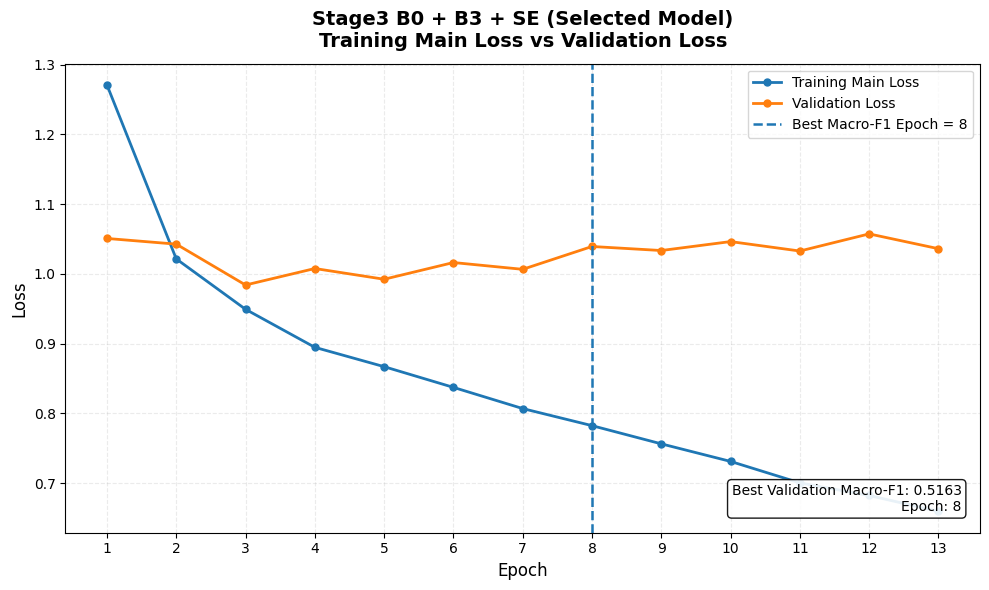

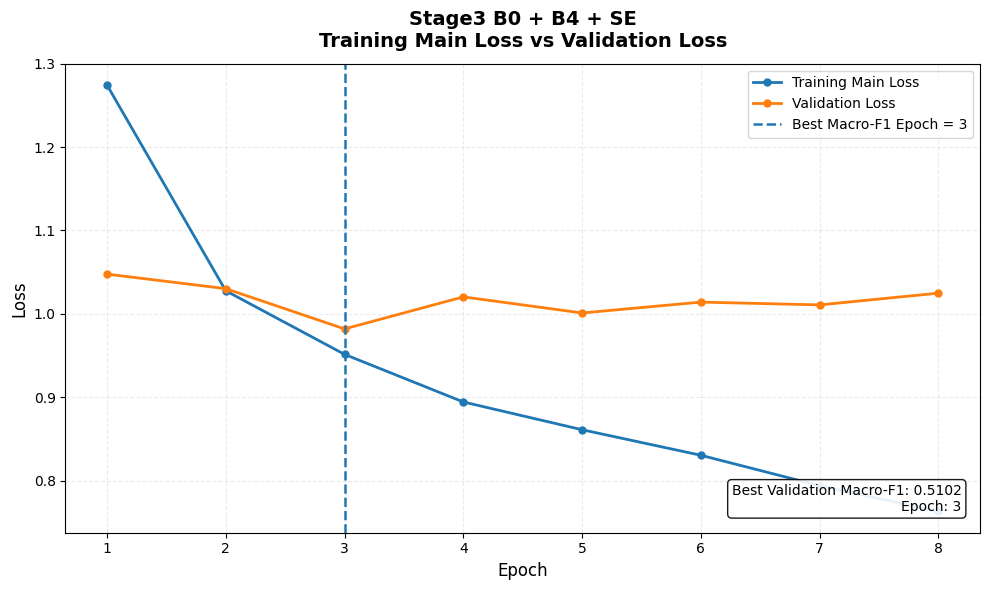

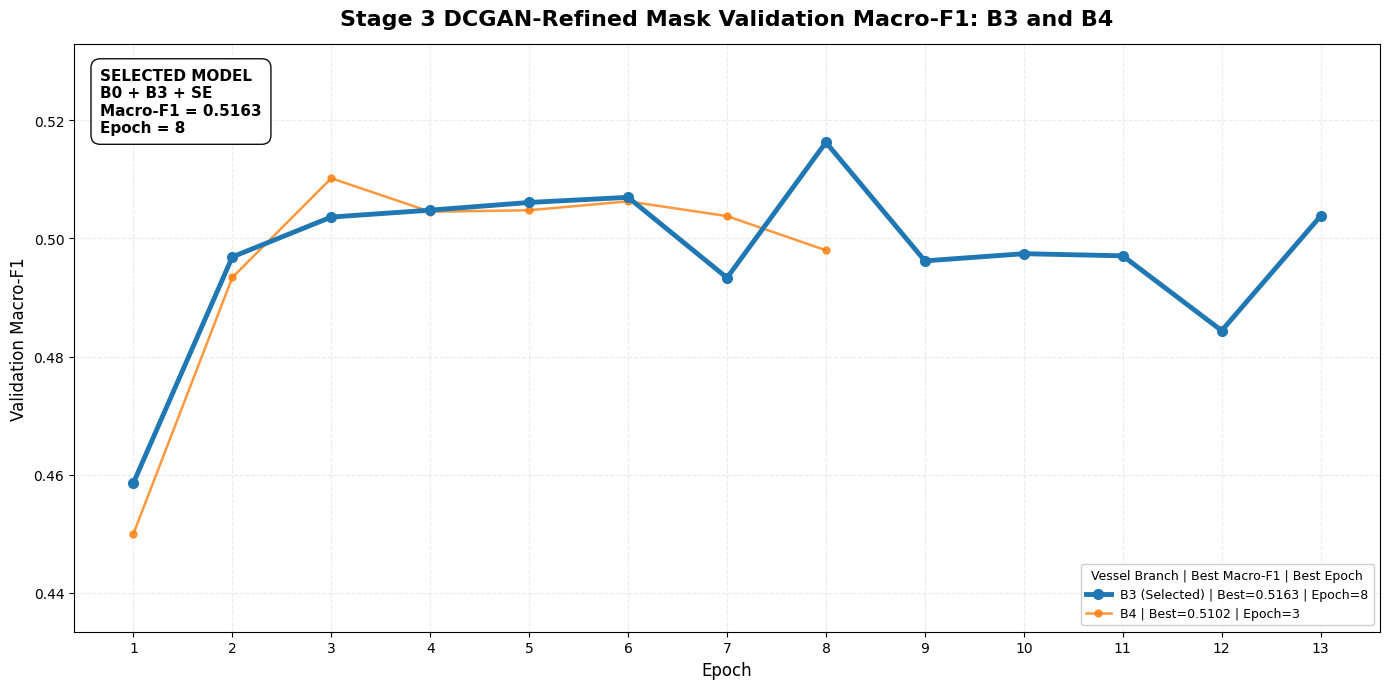


B1-B5 VALIDATION MACRO-F1 SUMMARY
Model  Best Validation Macro-F1  Best Epoch Selected
   B3                  0.516261           8      Yes
   B4                  0.510176           3       No

Selected model: B3

Training/validation loss plots:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/training_validation_curves

Validation Macro-F1 comparison plot:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/training_validation_curves/stage3_B1_B5_validation_macro_f1_model_selection.png

Validation Macro-F1 summary CSV:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/training_validation_curves/stage3_B1_B5_best_validation_macro_f1_summary.csv


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


STAGE3_DIR = OUT_DIR


CURVE_DIR = os.path.join(
    STAGE3_DIR,
    "training_validation_curves"
)


os.makedirs(
    CURVE_DIR,
    exist_ok=True
)


MODELS = ["B3", "B4"]


SELECTED_FILE = os.path.join(
    STAGE3_DIR,
    "SELECTED_MODEL_VALIDATION.csv"
)


BEST_MODEL = None


if os.path.exists(
    SELECTED_FILE
):

    selected_df = pd.read_csv(
        SELECTED_FILE
    )

    if not selected_df.empty:

        BEST_MODEL = str(
            selected_df.iloc[0][
                "selected_model"
            ]
        )


for model_name in MODELS:

    history_file = os.path.join(
        STAGE3_DIR,
        f"stage3_{model_name}_history.csv"
    )


    if not os.path.exists(
        history_file
    ):

        print(
            f"{model_name}: history file not found."
        )

        continue


    history_df = pd.read_csv(
        history_file
    )


    required_columns = {
        "epoch",
        "train_main_loss",
        "val_loss",
        "val_macro_f1"
    }


    if (
        history_df.empty
        or
        not required_columns.issubset(
            history_df.columns
        )
    ):

        print(
            f"{model_name}: required history data missing."
        )

        continue


    epochs = history_df[
        "epoch"
    ].values


    train_main_loss = history_df[
        "train_main_loss"
    ].values


    val_loss = history_df[
        "val_loss"
    ].values


    best_idx = history_df[
        "val_macro_f1"
    ].idxmax()


    best_epoch = int(
        history_df.loc[
            best_idx,
            "epoch"
        ]
    )


    best_f1 = float(
        history_df.loc[
            best_idx,
            "val_macro_f1"
        ]
    )


    fig, ax = plt.subplots(
        figsize=(
            10,
            6
        )
    )


    ax.plot(
        epochs,
        train_main_loss,
        marker="o",
        markersize=5,
        linewidth=2,
        label="Training Main Loss"
    )


    ax.plot(
        epochs,
        val_loss,
        marker="o",
        markersize=5,
        linewidth=2,
        label="Validation Loss"
    )


    ax.axvline(
        best_epoch,
        linestyle="--",
        linewidth=1.8,
        label=(
            f"Best Macro-F1 Epoch = "
            f"{best_epoch}"
        )
    )


    if (
        BEST_MODEL is not None
        and
        model_name == BEST_MODEL
    ):

        title = (
            f"Stage3 B0 + {model_name} + SE "
            "(Selected Model)\n"
            "Training Main Loss vs Validation Loss"
        )

    else:

        title = (
            f"Stage3 B0 + {model_name} + SE\n"
            "Training Main Loss vs Validation Loss"
        )


    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=12
    )


    ax.set_xlabel(
        "Epoch",
        fontsize=12
    )


    ax.set_ylabel(
        "Loss",
        fontsize=12
    )


    ax.set_xticks(
        epochs
    )


    ax.tick_params(
        axis="both",
        labelsize=10
    )


    ax.grid(
        True,
        linestyle="--",
        alpha=0.25
    )


    ax.legend(
        loc="best",
        fontsize=10,
        frameon=True
    )


    ax.text(
        0.98,
        0.04,
        (
            f"Best Validation Macro-F1: "
            f"{best_f1:.4f}\n"
            f"Epoch: {best_epoch}"
        ),
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=10,
        bbox=dict(
            boxstyle="round",
            facecolor="white",
            edgecolor="black",
            alpha=0.9
        )
    )


    plt.tight_layout()


    loss_plot_path = os.path.join(
        CURVE_DIR,
        f"stage3_{model_name}_training_vs_validation_loss.png"
    )


    plt.savefig(
        loss_plot_path,
        dpi=220,
        bbox_inches="tight"
    )


    plt.show()


    plt.close(
        fig
    )


fig, ax = plt.subplots(
    figsize=(
        14,
        7
    )
)


all_f1_values = []

max_epoch = 0

selected_best_epoch = None

selected_best_f1 = None

model_summary = []


for model_name in MODELS:

    history_file = os.path.join(
        STAGE3_DIR,
        f"stage3_{model_name}_history.csv"
    )


    if not os.path.exists(
        history_file
    ):

        continue


    history_df = pd.read_csv(
        history_file
    )


    if (
        history_df.empty
        or
        "epoch" not in history_df.columns
        or
        "val_macro_f1" not in history_df.columns
    ):

        continue


    epochs = history_df[
        "epoch"
    ].values


    val_macro_f1 = history_df[
        "val_macro_f1"
    ].values


    all_f1_values.extend(
        val_macro_f1.tolist()
    )


    max_epoch = max(
        max_epoch,
        int(
            np.max(
                epochs
            )
        )
    )


    best_idx = history_df[
        "val_macro_f1"
    ].idxmax()


    best_epoch = int(
        history_df.loc[
            best_idx,
            "epoch"
        ]
    )


    best_f1 = float(
        history_df.loc[
            best_idx,
            "val_macro_f1"
        ]
    )


    is_selected = (
        BEST_MODEL is not None
        and
        model_name == BEST_MODEL
    )


    if is_selected:

        ax.plot(
            epochs,
            val_macro_f1,
            marker="o",
            markersize=7,
            linewidth=3.5,
            zorder=5,
            label=(
                f"{model_name} (Selected) | "
                f"Best={best_f1:.4f} | "
                f"Epoch={best_epoch}"
            )
        )


        selected_best_epoch = (
            best_epoch
        )


        selected_best_f1 = (
            best_f1
        )


    else:

        ax.plot(
            epochs,
            val_macro_f1,
            marker="o",
            markersize=5,
            linewidth=1.8,
            alpha=0.80,
            label=(
                f"{model_name} | "
                f"Best={best_f1:.4f} | "
                f"Epoch={best_epoch}"
            )
        )


    model_summary.append(
        {
            "Model":
                model_name,

            "Best Validation Macro-F1":
                best_f1,

            "Best Epoch":
                best_epoch,

            "Selected":
                (
                    "Yes"
                    if is_selected
                    else "No"
                )
        }
    )


if len(
    all_f1_values
) == 0:

    raise RuntimeError(
        "No validation Macro-F1 history found."
    )


y_min = min(
    all_f1_values
)


y_max = max(
    all_f1_values
)


y_range = (
    y_max
    -
    y_min
)


y_padding = max(
    0.01,
    y_range * 0.25
)


ax.set_ylim(
    max(
        0,
        y_min - y_padding
    ),
    min(
        1,
        y_max + y_padding
    )
)


if max_epoch > 0:

    ax.set_xticks(
        np.arange(
            1,
            max_epoch + 1,
            1
        )
    )


ax.set_title(
    "Stage 3 DCGAN-Refined Mask Validation Macro-F1: B3 and B4",
    fontsize=16,
    fontweight="bold",
    pad=14
)


ax.set_xlabel(
    "Epoch",
    fontsize=12
)


ax.set_ylabel(
    "Validation Macro-F1",
    fontsize=12
)


ax.tick_params(
    axis="both",
    labelsize=10
)


ax.grid(
    True,
    linestyle="--",
    alpha=0.25
)


ax.legend(
    title=(
        "Vessel Branch | "
        "Best Macro-F1 | Best Epoch"
    ),
    loc="lower right",
    fontsize=9,
    title_fontsize=9,
    frameon=True,
    framealpha=0.95
)


if (
    selected_best_epoch is not None
    and
    selected_best_f1 is not None
):

    ax.text(
        0.02,
        0.96,
        (
            f"SELECTED MODEL\n"
            f"B0 + {BEST_MODEL} + SE\n"
            f"Macro-F1 = "
            f"{selected_best_f1:.4f}\n"
            f"Epoch = "
            f"{selected_best_epoch}"
        ),
        transform=ax.transAxes,
        fontsize=11,
        fontweight="bold",
        va="top",
        ha="left",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor="black",
            alpha=0.95
        )
    )


plt.tight_layout()


macro_f1_plot_path = os.path.join(
    CURVE_DIR,
    "stage3_B1_B5_validation_macro_f1_model_selection.png"
)


plt.savefig(
    macro_f1_plot_path,
    dpi=220,
    bbox_inches="tight"
)


plt.show()


plt.close(
    fig
)


model_summary_df = pd.DataFrame(
    model_summary
)


model_summary_df = (
    model_summary_df
    .sort_values(
        by=[
            "Best Validation Macro-F1"
        ],
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


summary_path = os.path.join(
    CURVE_DIR,
    "stage3_B1_B5_best_validation_macro_f1_summary.csv"
)


model_summary_df.to_csv(
    summary_path,
    index=False
)


print(
    "\n"
    + "=" * 80
)


print(
    "B1-B5 VALIDATION MACRO-F1 SUMMARY"
)


print(
    "=" * 80
)


print(
    model_summary_df.to_string(
        index=False
    )
)


print(
    "\nSelected model:",
    BEST_MODEL
)


print(
    "\nTraining/validation loss plots:"
)


print(
    CURVE_DIR
)


print(
    "\nValidation Macro-F1 comparison plot:"
)


print(
    macro_f1_plot_path
)


print(
    "\nValidation Macro-F1 summary CSV:"
)


print(
    summary_path
)


STAGE 1 - B0 RGB-ONLY TEST


Stage1 B0 RGB Test:   0%|          | 0/1318 [00:00<?, ?batch/s]


Stage 1 total test images: 5269
Test alignment verified: True

STAGE 1 CLASSIFICATION REPORT
                  precision    recall  f1-score   support

           no_dr     0.8409    0.8654    0.8530      3872
            mild     0.1245    0.1557    0.1383       366
        moderate     0.5303    0.4521    0.4881       794
          severe     0.5000    0.3053    0.3791       131
proliferative_dr     0.7826    0.5094    0.6171       106

        accuracy                         0.7328      5269
       macro avg     0.5556    0.4576    0.4951      5269
    weighted avg     0.7347    0.7328    0.7318      5269



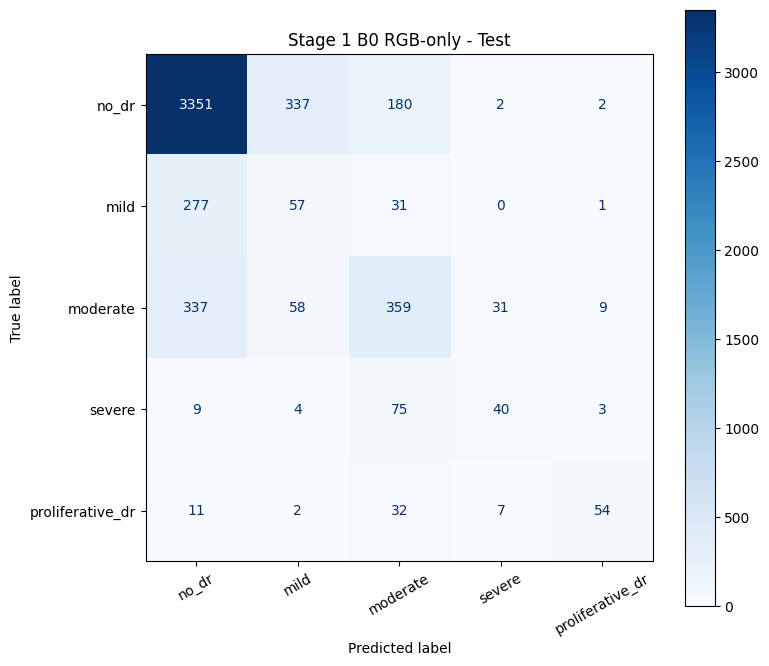


Stage 1 testing completed.

TESTING B0+B3+SE
Using DCGAN-refined Stage 3 masks


B0+B3+SE Test:   0%|          | 0/1318 [00:00<?, ?batch/s]


B0+B3+SE CLASSIFICATION REPORT
                  precision    recall  f1-score   support

           no_dr     0.8453    0.8765    0.8607      3872
            mild     0.1306    0.1503    0.1398       366
        moderate     0.5681    0.4622    0.5097       794
          severe     0.4902    0.3817    0.4292       131
proliferative_dr     0.7176    0.5755    0.6387       106

        accuracy                         0.7453      5269
       macro avg     0.5504    0.4892    0.5156      5269
    weighted avg     0.7425    0.7453    0.7425      5269



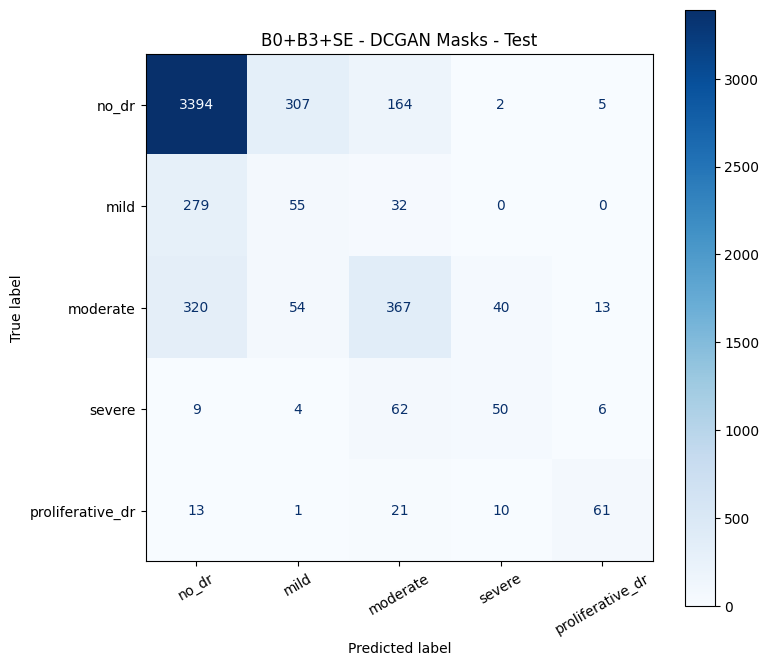


B0+B3+SE testing completed.

TESTING B0+B4+SE
Using DCGAN-refined Stage 3 masks


B0+B4+SE Test:   0%|          | 0/1318 [00:00<?, ?batch/s]


B0+B4+SE CLASSIFICATION REPORT
                  precision    recall  f1-score   support

           no_dr     0.8437    0.9217    0.8810      3872
            mild     0.1829    0.0874    0.1183       366
        moderate     0.5613    0.4496    0.4993       794
          severe     0.4690    0.4046    0.4344       131
proliferative_dr     0.5913    0.6415    0.6154       106

        accuracy                         0.7742      5269
       macro avg     0.5296    0.5010    0.5097      5269
    weighted avg     0.7409    0.7742    0.7541      5269



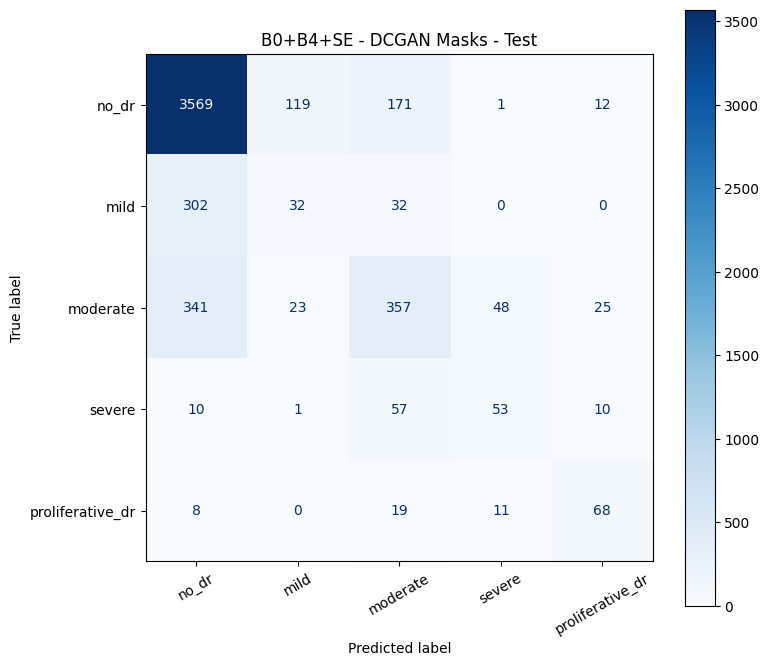


B0+B4+SE testing completed.

OVERALL TEST COMPARISON
                 Model  Accuracy  Macro F1  Weighted F1  Macro Precision  Macro Recall  Macro AUROC
    Stage1 B0 RGB-only    0.7328    0.4951       0.7318           0.5556        0.4576       0.8122
B0+B3+SE (DCGAN masks)    0.7453    0.5156       0.7425           0.5504        0.4892       0.8044
B0+B4+SE (DCGAN masks)    0.7742    0.5097       0.7541           0.5296        0.5010       0.8283

PER-CLASS RECALL
           Class  Stage1 B0 RGB-only  B0+B3+SE  B0+B4+SE
           no_dr              0.8654    0.8765    0.9217
            mild              0.1557    0.1503    0.0874
        moderate              0.4521    0.4622    0.4496
          severe              0.3053    0.3817    0.4046
proliferative_dr              0.5094    0.5755    0.6415


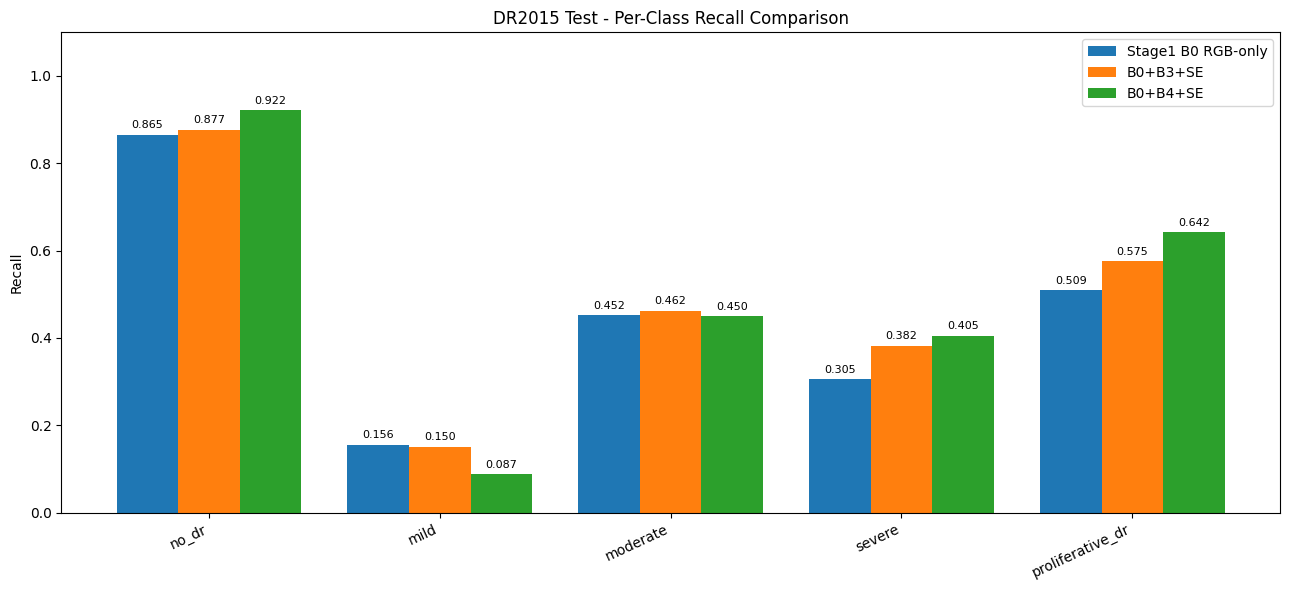


Visualization model: B0+B3+SE
s1_labels: (5269,)
s1_preds: (5269,)
s1_probs: (5269, 5)
s3_labels: (5269,)
s3_preds: (5269,)
s3_probs: (5269, 5)

ALL THREE MODEL TESTS COMPLETED

Models evaluated:
1. Stage1 B0 RGB-only
2. B0+B3+SE with DCGAN-refined masks
3. B0+B4+SE with DCGAN-refined masks

Final comparison:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/final_test_results_both_B3_B4/Stage1_vs_B0_B3_SE_vs_B0_B4_SE.csv

Per-class recall:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/final_test_results_both_B3_B4/per_class_recall_B3_B4.csv

All results saved locally:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/final_test_results_both_B3_B4


In [ ]:

# ============================================================
# CELL 15 - COMPLETE FINAL TESTING
#
# STAGE 1: B0 RGB ONLY
# STAGE 3: B0+B3+SE WITH DCGAN-REFINED MASKS
# STAGE 3: B0+B4+SE WITH DCGAN-REFINED MASKS
#
# NO RETRAINING REQUIRED
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required = [
    "OUT_DIR",
    "stage1",
    "Stage3EfficientNetB0BxSE",
    "stage3_test_ds",
    "test_df",
    "num_classes",
    "CLASS_NAMES",
    "device"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run the dataset and model setup cells first. Missing: "
        + ", ".join(missing)
    )

# ============================================================
# 2. OUTPUT FOLDER AND MODEL INFORMATION
# ============================================================

FINAL_DIR = (
    Path(OUT_DIR) / "final_test_results_both_B3_B4"
)

FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

stage1_weight_value = (
    globals().get("LOCAL_STAGE1_W")
    or globals().get("STAGE1_W")
)

if not stage1_weight_value:
    raise RuntimeError("Stage 1 weight path is missing.")

STAGE1_WEIGHTS = Path(stage1_weight_value)

if not STAGE1_WEIGHTS.is_file():
    raise FileNotFoundError(STAGE1_WEIGHTS)

MODEL_NAMES = {
    "B3": "tf_efficientnet_b3.ns_jft_in1k",
    "B4": "tf_efficientnet_b4.ns_jft_in1k"
}

ALL_CLASSES = list(range(num_classes))

expected_labels = (
    test_df["label"].to_numpy(dtype=int)
)

summary_rows = []

recall_table = pd.DataFrame({
    "Class": CLASS_NAMES
})

stage3_predictions_by_model = {}

AMP_ENABLED = torch.cuda.is_available()

NUM_WORKERS = min(
    4,
    globals().get("STAGE3_NUM_WORKERS", 0)
)

# ============================================================
# 3. DEFINE METRIC FUNCTION
# ============================================================

def calculate_test_metrics(
    model_name,
    y_true,
    y_pred,
    probabilities
):

    scores = {

        "Model": model_name,

        "Accuracy": accuracy_score(
            y_true, y_pred
        ),

        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro AUROC": np.nan
    }

    try:

        scores["Macro AUROC"] = roc_auc_score(
            y_true,
            probabilities,
            labels=ALL_CLASSES,
            multi_class="ovr",
            average="macro"
        )

    except ValueError as error:

        print(
            f"{model_name} AUROC warning:",
            error
        )

    return scores


# ============================================================
# 4. DEFINE CONFUSION MATRIX FUNCTION
# ============================================================

def save_confusion_matrix(
    y_true,
    y_pred,
    title,
    filename
):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=ALL_CLASSES
    )

    pd.DataFrame(
        cm,
        index=CLASS_NAMES,
        columns=CLASS_NAMES
    ).to_csv(
        FINAL_DIR / f"{filename}.csv"
    )

    fig, ax = plt.subplots(
        figsize=(8, 7)
    )

    ConfusionMatrixDisplay(
        cm,
        display_labels=CLASS_NAMES
    ).plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=30,
        colorbar=True,
        values_format="d"
    )

    ax.set_title(title)

    plt.tight_layout()

    plt.savefig(
        FINAL_DIR / f"{filename}.png",
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    return cm


# ============================================================
# 5. STAGE 1 - B0 RGB-ONLY TEST
# ============================================================

print("\n" + "=" * 70)
print("STAGE 1 - B0 RGB-ONLY TEST")
print("=" * 70)

stage1 = stage1.to(device)
stage1.eval()

stage1_loader = DataLoader(
    stage3_test_ds,
    batch_size=4,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=AMP_ENABLED
)

s1_labels = []
s1_preds = []
s1_probs = []

with torch.inference_mode():

    for rgb, mask, labels in tqdm(
        stage1_loader,
        desc="Stage1 B0 RGB Test",
        unit="batch"
    ):

        rgb = rgb.to(
            device,
            non_blocking=True
        )

        # Stage 1 uses RGB only.
        # Vessel masks are NOT passed to Stage 1.

        with torch.amp.autocast(
            device_type="cuda",
            enabled=AMP_ENABLED
        ):

            logits = stage1(rgb)

        probs = torch.softmax(
            logits.float(),
            dim=1
        )

        s1_labels.extend(
            labels.cpu().numpy()
        )

        s1_preds.extend(
            probs.argmax(dim=1).cpu().numpy()
        )

        s1_probs.extend(
            probs.cpu().numpy()
        )

s1_labels = np.asarray(
    s1_labels,
    dtype=int
)

s1_preds = np.asarray(
    s1_preds,
    dtype=int
)

s1_probs = np.asarray(
    s1_probs,
    dtype=float
)

# ============================================================
# 6. VERIFY STAGE 1 TEST ALIGNMENT
# ============================================================

if not np.array_equal(
    s1_labels,
    expected_labels
):
    raise RuntimeError(
        "Stage 1 test labels/order do not match test_df."
    )

if s1_probs.shape != (
    len(expected_labels),
    num_classes
):
    raise RuntimeError(
        "Stage 1 probability shape mismatch."
    )

print("\nStage 1 total test images:", len(s1_labels))
print("Test alignment verified:", True)

# ============================================================
# 7. STAGE 1 METRICS
# ============================================================

stage1_scores = calculate_test_metrics(
    "Stage1 B0 RGB-only",
    s1_labels,
    s1_preds,
    s1_probs
)

summary_rows.append(stage1_scores)

recall_table[
    "Stage1 B0 RGB-only"
] = recall_score(
    s1_labels,
    s1_preds,
    labels=ALL_CLASSES,
    average=None,
    zero_division=0
)

print("\nSTAGE 1 CLASSIFICATION REPORT")

print(
    classification_report(
        s1_labels,
        s1_preds,
        labels=ALL_CLASSES,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

CM1 = save_confusion_matrix(
    s1_labels,
    s1_preds,
    "Stage 1 B0 RGB-only - Test",
    "Stage1_B0_confusion_matrix"
)

# Save Stage 1 prediction scores
stage1_predictions = test_df[
    ["basename", "label"]
].copy()

stage1_predictions["predicted_label"] = s1_preds

stage1_predictions["predicted_class"] = [
    CLASS_NAMES[int(p)]
    for p in s1_preds
]

stage1_predictions["prediction_confidence"] = (
    s1_probs.max(axis=1)
)

for i, cls in enumerate(CLASS_NAMES):

    stage1_predictions[
        f"prob_{cls}"
    ] = s1_probs[:, i]

stage1_predictions.to_csv(
    FINAL_DIR / "Stage1_B0_test_predictions.csv",
    index=False
)

# Move Stage 1 to CPU to free GPU memory
stage1.cpu()

del stage1_loader

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nStage 1 testing completed.")

# ============================================================
# 8. TEST BOTH STAGE 3 MODELS
# ============================================================

for short, timm_name in MODEL_NAMES.items():

    checkpoint = (
        Path(OUT_DIR) / f"stage3_{short}_best.pth"
    )

    if not checkpoint.is_file():
        raise FileNotFoundError(
            f"Missing trained {short} checkpoint: {checkpoint}"
        )

    print("\n" + "=" * 70)
    print(f"TESTING B0+{short}+SE")
    print("Using DCGAN-refined Stage 3 masks")
    print("=" * 70)

    batch_by_model = globals().get(
        "BATCH_BY_MODEL", {}
    )

    batch_size = min(
        4,
        batch_by_model.get(short, 4)
    )

    # ========================================================
    # LOAD TEST DATA
    # ========================================================

    loader = DataLoader(
        stage3_test_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=AMP_ENABLED
    )

    # ========================================================
    # LOAD TRAINED MODEL
    # ========================================================

    model = Stage3EfficientNetB0BxSE(
        num_classes,
        str(STAGE1_WEIGHTS),
        timm_name,
        mask_pretrained=False
    ).to(device)

    checkpoint_state = torch.load(
        checkpoint,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint_state,
        strict=True
    )

    del checkpoint_state

    model.eval()

    # ========================================================
    # GENERATE TEST PREDICTIONS
    # ========================================================

    y_true = []
    y_pred = []
    prob_list = []

    with torch.inference_mode():

        for rgb, mask, labels in tqdm(
            loader,
            desc=f"B0+{short}+SE Test",
            unit="batch"
        ):

            rgb = rgb.to(
                device,
                non_blocking=True
            )

            mask = mask.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=AMP_ENABLED
            ):

                logits = model(
                    rgb,
                    mask
                )

            probs = torch.softmax(
                logits.float(),
                dim=1
            )

            y_true.extend(
                labels.cpu().numpy()
            )

            y_pred.extend(
                probs.argmax(dim=1).cpu().numpy()
            )

            prob_list.extend(
                probs.cpu().numpy()
            )

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int
    )

    probabilities = np.asarray(
        prob_list,
        dtype=float
    )

    # ========================================================
    # VERIFY TEST SET
    # ========================================================

    if not np.array_equal(
        y_true,
        expected_labels
    ):
        raise RuntimeError(
            f"B0+{short}+SE test labels/order do not match."
        )

    if probabilities.shape != (
        len(expected_labels),
        num_classes
    ):
        raise RuntimeError(
            f"B0+{short}+SE probability shape mismatch."
        )

    # Retain predictions for visualization
    stage3_predictions_by_model[short] = {
        "labels": y_true.copy(),
        "preds": y_pred.copy(),
        "probs": probabilities.copy()
    }

    # ========================================================
    # OVERALL TEST METRICS
    # ========================================================

    scores = calculate_test_metrics(
        f"B0+{short}+SE (DCGAN masks)",
        y_true,
        y_pred,
        probabilities
    )

    summary_rows.append(scores)

    recall_table[
        f"B0+{short}+SE"
    ] = recall_score(
        y_true,
        y_pred,
        labels=ALL_CLASSES,
        average=None,
        zero_division=0
    )

    print(
        f"\nB0+{short}+SE CLASSIFICATION REPORT"
    )

    print(
        classification_report(
            y_true,
            y_pred,
            labels=ALL_CLASSES,
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0
        )
    )

    report_dict = classification_report(
        y_true,
        y_pred,
        labels=ALL_CLASSES,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame(
        report_dict
    ).T.to_csv(
        FINAL_DIR
        / f"B0_{short}_SE_classification_report.csv"
    )

    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    cm = save_confusion_matrix(
        y_true,
        y_pred,
        f"B0+{short}+SE - DCGAN Masks - Test",
        f"B0_{short}_SE_confusion_matrix"
    )

    # ========================================================
    # SAVE PER-IMAGE PREDICTION SCORES
    # ========================================================

    per_image = test_df[
        [
            "basename",
            "label",
            "class_name",
            "stage3_mask_path"
        ]
    ].copy()

    per_image[
        "predicted_label"
    ] = y_pred

    per_image[
        "predicted_class"
    ] = [
        CLASS_NAMES[int(p)]
        for p in y_pred
    ]

    per_image[
        "prediction_confidence"
    ] = probabilities.max(axis=1)

    per_image[
        "actual_class_probability"
    ] = probabilities[
        np.arange(len(y_true)),
        y_true
    ]

    for i, cls in enumerate(CLASS_NAMES):

        per_image[
            f"prob_{cls}"
        ] = probabilities[:, i]

    per_image.to_csv(
        FINAL_DIR / f"B0_{short}_SE_predictions.csv",
        index=False
    )

    print(f"\nB0+{short}+SE testing completed.")

    # ========================================================
    # RELEASE GPU MEMORY
    # ========================================================

    del model, loader

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ============================================================
# 9. COMPLETE TEST COMPARISON
# ============================================================

summary_df = pd.DataFrame(
    summary_rows
)

summary_df.to_csv(
    FINAL_DIR
    / "Stage1_vs_B0_B3_SE_vs_B0_B4_SE.csv",
    index=False
)

recall_table.to_csv(
    FINAL_DIR
    / "per_class_recall_B3_B4.csv",
    index=False
)

print("\n" + "=" * 90)
print("OVERALL TEST COMPARISON")
print("=" * 90)

print(
    summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 90)
print("PER-CLASS RECALL")
print("=" * 90)

print(
    recall_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ============================================================
# 10. PER-CLASS RECALL COMPARISON PLOT
# ============================================================

x = np.arange(num_classes)

columns = list(
    recall_table.columns[1:]
)

width = 0.8 / len(columns)

fig, ax = plt.subplots(
    figsize=(13, 6)
)

for i, column in enumerate(columns):

    values = recall_table[
        column
    ].to_numpy(dtype=float)

    bars = ax.bar(
        x + (
            i - (len(columns) - 1) / 2
        ) * width,
        values,
        width,
        label=column
    )

    for bar in bars:

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.3f}",
            ha="center",
            fontsize=8
        )

ax.set_xticks(
    x,
    CLASS_NAMES,
    rotation=25,
    ha="right"
)

ax.set_ylim(0, 1.10)

ax.set_ylabel("Recall")

ax.set_title(
    "DR2015 Test - Per-Class Recall Comparison"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    FINAL_DIR
    / "per_class_recall_comparison.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ============================================================
# 11. VARIABLES FOR FIVE-SEVERITY VISUALIZATION
# ============================================================

# Select the model for your next visualization cell.
# Change to "B4" when you want B4 examples.

BEST_MODEL = globals().get(
    "BEST_MODEL", "B3"
)

if BEST_MODEL not in ("B3", "B4"):
    BEST_MODEL = "B3"

s3_labels = stage3_predictions_by_model[
    BEST_MODEL
]["labels"]

s3_preds = stage3_predictions_by_model[
    BEST_MODEL
]["preds"]

s3_probs = stage3_predictions_by_model[
    BEST_MODEL
]["probs"]

print(
    "\nVisualization model:",
    f"B0+{BEST_MODEL}+SE"
)

print("s1_labels:", s1_labels.shape)
print("s1_preds:", s1_preds.shape)
print("s1_probs:", s1_probs.shape)

print("s3_labels:", s3_labels.shape)
print("s3_preds:", s3_preds.shape)
print("s3_probs:", s3_probs.shape)

# ============================================================
# 12. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 90)
print("ALL THREE MODEL TESTS COMPLETED")
print("=" * 90)

print("\nModels evaluated:")
print("1. Stage1 B0 RGB-only")
print("2. B0+B3+SE with DCGAN-refined masks")
print("3. B0+B4+SE with DCGAN-refined masks")

print("\nFinal comparison:")
print(
    FINAL_DIR
    / "Stage1_vs_B0_B3_SE_vs_B0_B4_SE.csv"
)

print("\nPer-class recall:")
print(
    FINAL_DIR
    / "per_class_recall_B3_B4.csv"
)

print("\nAll results saved locally:")
print(FINAL_DIR)


Loaded trained B0+B3+SE checkpoint.
Checkpoint: /content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/stage3_B3_best.pth


B3 Validation:   0%|          | 0/1318 [00:00<?, ?batch/s]

B3 :   0%|          | 0/327 [00:00<?, ?it/s]


Evaluating final test images...


B3 Final Test:   0%|          | 0/1318 [00:00<?, ?batch/s]


FINAL TEST COMPARISON
                 Stage1 B0  B3 Original  B3 Calibrated  Gain vs Stage1 (pp)
Accuracy            0.7328       0.7453         0.7497               1.6891
Macro F1            0.4951       0.5156         0.5106               1.5451
Weighted F1         0.7318       0.7425         0.7419               1.0060
Macro Precision     0.5556       0.5504         0.5589               0.3212
Macro Recall        0.4576       0.4892         0.4780               2.0410
Macro AUROC         0.8122       0.8044         0.8109              -0.1279

All six test metrics above Stage1: False

B3 CALIBRATED CLASSIFICATION REPORT
                  precision    recall  f1-score   support

           no_dr     0.8380    0.8951    0.8656      3872
            mild     0.1283    0.1448    0.1361       366
        moderate     0.6000    0.4043    0.4831       794
          severe     0.4811    0.3893    0.4304       131
proliferative_dr     0.7468    0.5566    0.6378       106

        accuracy

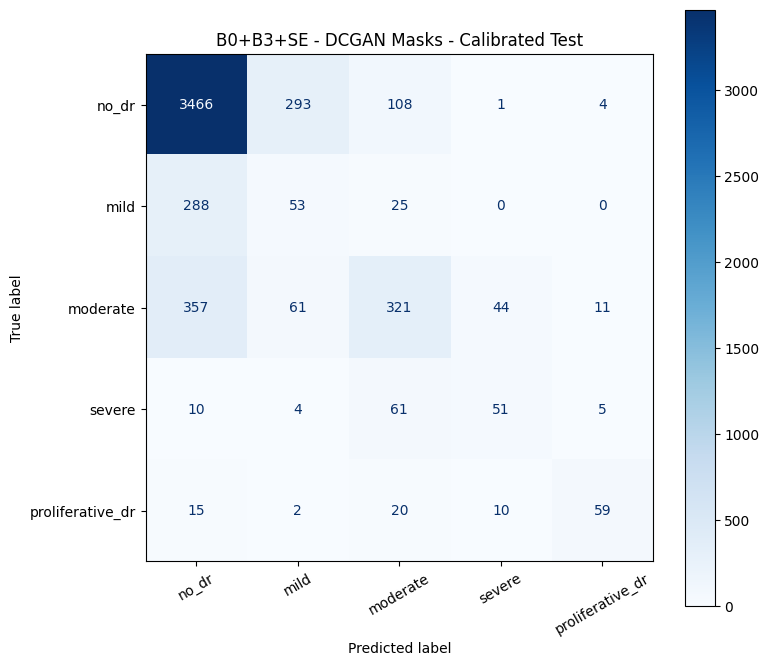


B3 VALIDATION-ONLY CALIBRATION COMPLETED

Calibration checkpoint:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/stage3_B3_best.pth

Calibration parameters:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/B3/B3_selected_calibration.npz

Test comparison:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/B3/B3_calibrated_test_metrics.csv

Confusion matrix:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/B3/B3_calibrated_confusion_matrix.png

Prediction scores:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/B3/B3_calibrated_predictions.csv

All results saved locally:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/B3


In [ ]:
import gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)



required = [
    "OUT_DIR",
    "Stage3EfficientNetB0BxSE",
    "stage1",
    "stage3_val_ds",
    "stage3_test_ds",
    "val_df",
    "test_df",
    "num_classes",
    "CLASS_NAMES",
    "device",
    "STAGE1_W"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run the model and dataset setup cells first. Missing: "
        + ", ".join(missing)
    )



CAL_DIR = Path(OUT_DIR) / "B3"
CAL_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT = Path(OUT_DIR) / "stage3_B3_best.pth"

if not CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"B3 trained checkpoint not found: {CHECKPOINT}"
    )

STAGE1_WEIGHTS = Path(
    globals().get("LOCAL_STAGE1_W", STAGE1_W)
)

if not STAGE1_WEIGHTS.is_file():
    raise FileNotFoundError(STAGE1_WEIGHTS)

if torch.cuda.is_available():
    torch.cuda.empty_cache()



b3 = Stage3EfficientNetB0BxSE(
    num_classes,
    str(STAGE1_WEIGHTS),
    "tf_efficientnet_b3.ns_jft_in1k",
    mask_pretrained=False
).to(device)

checkpoint_state = torch.load(
    CHECKPOINT,
    map_location=device,
    weights_only=False
)

b3.load_state_dict(
    checkpoint_state,
    strict=True
)

b3.eval()

# Stage 1 baseline model
stage1 = stage1.to(device)
stage1.eval()

print("Loaded trained B0+B3+SE checkpoint.")
print("Checkpoint:", CHECKPOINT)



def make_calibration_loader(dataset):

    return DataLoader(
        dataset,
        batch_size=4,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )



@torch.inference_mode()
def collect_logits(dataset, dataframe, description):

    labels_all = []
    b3_logits = []
    stage1_logits = []

    loader = make_calibration_loader(dataset)

    for rgb, mask, labels in tqdm(
        loader,
        desc=description,
        unit="batch"
    ):

        rgb = rgb.to(
            device,
            non_blocking=True
        )

        mask = mask.to(
            device,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):

            logits_b3 = b3(rgb, mask)

            logits_stage1 = stage1(rgb)

        b3_logits.append(
            logits_b3.float().cpu().numpy()
        )

        stage1_logits.append(
            logits_stage1.float().cpu().numpy()
        )

        labels_all.extend(
            labels.cpu().numpy()
        )

    y = np.asarray(
        labels_all,
        dtype=int
    )

    expected = dataframe[
        "label"
    ].to_numpy(dtype=int)

    if not np.array_equal(y, expected):
        raise RuntimeError(
            "Dataset labels or order do not match."
        )

    return (
        y,
        np.concatenate(b3_logits, axis=0),
        np.concatenate(stage1_logits, axis=0)
    )




def to_probabilities(logits):

    z = np.asarray(
        logits,
        dtype=np.float64
    )

    z = z - z.max(
        axis=1,
        keepdims=True
    )

    exp_z = np.exp(z)

    return exp_z / exp_z.sum(
        axis=1,
        keepdims=True
    )




METRICS = [
    "Accuracy",
    "Macro F1",
    "Weighted F1",
    "Macro Precision",
    "Macro Recall",
    "Macro AUROC"
]


def calculate_scores(labels, probabilities):

    predictions = probabilities.argmax(axis=1)

    scores = {
        "Accuracy": accuracy_score(
            labels, predictions
        ),

        "Macro F1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Macro Precision": precision_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Macro AUROC": np.nan
    }

    try:
        scores["Macro AUROC"] = roc_auc_score(
            labels,
            probabilities,
            labels=list(range(num_classes)),
            multi_class="ovr",
            average="macro"
        )

    except ValueError as error:
        print("AUROC unavailable:", error)

    return scores




y_val, z_val, z_stage1_val = collect_logits(
    stage3_val_ds,
    val_df,
    "B3 Validation"
)

stage1_val_scores = calculate_scores(
    y_val,
    to_probabilities(z_stage1_val)
)

original_b3_val_scores = calculate_scores(
    y_val,
    to_probabilities(z_val)
)






rng = np.random.default_rng(42)

candidates = [
    (
        1.0,
        np.ones(num_classes),
        np.zeros(num_classes)
    )
]

# Temperature and individual class adjustments
for temperature in [
    0.70, 0.85, 1.0, 1.2, 1.5, 2.0
]:

    candidates.append((
        temperature,
        np.ones(num_classes),
        np.zeros(num_classes)
    ))

    for cls in range(num_classes):

        for offset in [
            -0.30,
            -0.18,
            -0.08,
             0.08,
             0.18,
             0.30
        ]:

            biases = np.zeros(num_classes)

            biases[cls] = offset

            candidates.append((
                temperature,
                np.ones(num_classes),
                biases
            ))


# Small joint adjustments
for _ in range(140):

    temperature = float(
        rng.uniform(0.7, 1.8)
    )

    scales = np.exp(
        rng.normal(
            0,
            0.07,
            num_classes
        )
    )

    biases = rng.normal(
        0,
        0.13,
        num_classes
    )

    biases -= biases.mean()

    candidates.append((
        temperature,
        scales,
        biases
    ))




# ===

best = None
history = []

for idx, (temperature, scales, biases) in enumerate(
    tqdm(
        candidates,
        desc="B3 "
    )
):

    adjusted_logits = (
        z_val * scales[None, :]
    ) / temperature + biases[None, :]

    probabilities = to_probabilities(
        adjusted_logits
    )

    scores = calculate_scores(
        y_val,
        probabilities
    )

    gains = np.array([
        scores[metric] - stage1_val_scores[metric]
        for metric in METRICS
    ])

    if not np.isfinite(gains).all():
        continue

    improved_count = int(
        np.sum(gains > 0)
    )

    all_improved = (
        improved_count == len(METRICS)
    )

    ranking = (
        int(all_improved),
        improved_count,
        float(gains.min()),
        float(gains.mean()),
        float(scores["Macro F1"])
    )

    history.append({
        "Candidate": idx,
        "Temperature": temperature,
        "Metrics above Stage1": improved_count,
        **scores
    })

    if best is None or ranking > best["ranking"]:

        best = {
            "ranking": ranking,
            "temperature": temperature,
            "scales": scales.copy(),
            "biases": biases.copy(),
            "scores": scores.copy()
        }


if best is None:
    raise RuntimeError(
        "No  candidates found."
    )






print("\nEvaluating final test images...")

y_test, z_test, z_stage1_test = collect_logits(
    stage3_test_ds,
    test_df,
    "B3 Final Test"
)

stage1_probs = to_probabilities(
    z_stage1_test
)

original_probs = to_probabilities(
    z_test
)

calibrated_logits = (
    z_test * best["scales"][None, :]
) / best["temperature"] + best["biases"][None, :]

calibrated_probs = to_probabilities(
    calibrated_logits
)




comparison = pd.DataFrame({
    "Stage1 B0": calculate_scores(
        y_test,
        stage1_probs
    ),

    "B3 Original": calculate_scores(
        y_test,
        original_probs
    ),

    "B3 Calibrated": calculate_scores(
        y_test,
        calibrated_probs
    )
})

comparison["Gain vs Stage1 (pp)"] = (
    comparison["B3 Calibrated"]
    - comparison["Stage1 B0"]
) * 100

print("\n" + "=" * 70)
print("FINAL TEST COMPARISON")
print("=" * 70)

print(
    comparison.round(4).to_string()
)

comparison.to_csv(
    CAL_DIR / "B3_calibrated_test_metrics.csv"
)

all_improved_test = all(
    comparison.loc[
        metric,
        "Gain vs Stage1 (pp)"
    ] > 0
    for metric in METRICS
)

print(
    "\nAll six test metrics above Stage1:",
    all_improved_test
)


# ============================================================
# 14. CLASSIFICATION REPORT
# ============================================================

y_pred = calibrated_probs.argmax(axis=1)

print("\nB3 CALIBRATED CLASSIFICATION REPORT")

report = classification_report(
    y_test,
    y_pred,
    labels=list(range(num_classes)),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

print(report)

report_dict = classification_report(
    y_test,
    y_pred,
    labels=list(range(num_classes)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).T.to_csv(
    CAL_DIR / "B3_calibrated_classification_report.csv"
)


# ============================================================
# 15. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(num_classes))
)

pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    CAL_DIR / "B3_calibrated_confusion_matrix.csv"
)

fig, ax = plt.subplots(
    figsize=(8, 7)
)

ConfusionMatrixDisplay(
    cm,
    display_labels=CLASS_NAMES
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=30,
    colorbar=True
)

ax.set_title(
    "B0+B3+SE - DCGAN Masks - Calibrated Test"
)

plt.tight_layout()

plt.savefig(
    CAL_DIR / "B3_calibrated_confusion_matrix.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 16. SAVE INDIVIDUAL PREDICTION SCORES
# ============================================================

predictions = test_df[
    [
        "basename",
        "label",
        "stage3_mask_path"
    ]
].copy()

predictions["predicted_label"] = y_pred

predictions["predicted_class"] = [
    CLASS_NAMES[int(p)]
    for p in y_pred
]

predictions["confidence"] = (
    calibrated_probs.max(axis=1)
)

predictions["actual_class_probability"] = (
    calibrated_probs[
        np.arange(len(y_test)),
        y_test
    ]
)

for i, name in enumerate(CLASS_NAMES):

    predictions[f"prob_{name}"] = (
        calibrated_probs[:, i]
    )

predictions.to_csv(
    CAL_DIR / "B3_calibrated_predictions.csv",
    index=False
)



print("\n" + "=" * 70)
print("B3 VALIDATION-ONLY CALIBRATION COMPLETED")
print("=" * 70)

print("\nCalibration checkpoint:")
print(CHECKPOINT)

print("\nCalibration parameters:")
print(CAL_DIR / "B3_selected_calibration.npz")

print("\nTest comparison:")
print(CAL_DIR / "B3_calibrated_test_metrics.csv")

print("\nConfusion matrix:")
print(CAL_DIR / "B3_calibrated_confusion_matrix.png")

print("\nPrediction scores:")
print(CAL_DIR / "B3_calibrated_predictions.csv")

print("\nAll results saved locally:")
print(CAL_DIR)

# Free GPU memory
del b3
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


In [ ]:

# ============================================================
# LOAD B0+B3+SE OR B0+B4+SE TEST PREDICTIONS
# FOR FIVE DR SEVERITY IMAGE VISUALIZATION
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

# Select model: "B3" or "B4"
BEST_MODEL = "B3"

# Use calibrated B3 results only if desired
USE_CALIBRATED_B3 = False

# ============================================================
# 1. LOCATE SAVED PREDICTIONS
# ============================================================

if BEST_MODEL not in ("B3", "B4"):
    raise ValueError("BEST_MODEL must be B3 or B4.")

if USE_CALIBRATED_B3:

    if BEST_MODEL != "B3":
        raise ValueError(
            "Calibrated prediction file is available for B3 only."
        )

    prediction_file = (
        Path(OUT_DIR)
        / "B3_validation_calibration"
        / "B3_calibrated_predictions.csv"
    )

else:

    prediction_file = (
        Path(OUT_DIR)
        / "final_test_results_both_B3_B4"
        / f"B0_{BEST_MODEL}_SE_predictions.csv"
    )

if not prediction_file.is_file():
    raise FileNotFoundError(
        f"Prediction CSV not found: {prediction_file}\n"
        "Run the B3/B4 final testing cell first."
    )

print("Loading model:", BEST_MODEL)
print("Prediction CSV:", prediction_file)

# ============================================================
# 2. LOAD SAVED TEST PREDICTIONS
# ============================================================

pred_df = pd.read_csv(prediction_file)

if "basename" not in test_df.columns:
    raise KeyError("test_df is missing basename.")

if test_df["basename"].duplicated().any():
    raise RuntimeError("Duplicate image IDs in test_df.")

if pred_df["basename"].duplicated().any():
    raise RuntimeError("Duplicate image IDs in prediction CSV.")

# Align predictions with exact test dataframe order
aligned = test_df[["basename"]].merge(
    pred_df,
    on="basename",
    how="left",
    validate="one_to_one",
    sort=False,
    indicator=True
)

if not (aligned["_merge"] == "both").all():
    missing_ids = aligned.loc[
        aligned["_merge"] != "both", "basename"
    ].tolist()

    raise RuntimeError(
        f"Missing predictions for {len(missing_ids)} images: "
        f"{missing_ids[:5]}"
    )

# ============================================================
# 3. RECOVER REQUIRED VARIABLES
# ============================================================

probability_columns = [
    f"prob_{name}"
    for name in CLASS_NAMES
]

required_columns = [
    "label",
    "predicted_label",
    *probability_columns
]

missing_columns = [
    c for c in required_columns
    if c not in aligned.columns
]

if missing_columns:
    raise KeyError(
        f"Missing CSV columns: {missing_columns}"
    )

s3_labels = aligned["label"].to_numpy(dtype=int)

s3_preds = aligned[
    "predicted_label"
].to_numpy(dtype=int)

s3_probs = aligned[
    probability_columns
].to_numpy(dtype=float)

# ============================================================
# 4. VERIFY ALL PREDICTIONS
# ============================================================

if len(s3_labels) != len(test_df):
    raise RuntimeError("Test image count mismatch.")

if not np.array_equal(
    s3_labels,
    test_df["label"].to_numpy(dtype=int)
):
    raise RuntimeError("Test labels do not match.")

if not np.isfinite(s3_probs).all():
    raise RuntimeError("Invalid probability values.")

if not np.allclose(
    s3_probs.sum(axis=1),
    1.0,
    atol=1e-4
):
    raise RuntimeError("Probabilities do not sum to 1.")

if not np.array_equal(
    s3_preds,
    s3_probs.argmax(axis=1)
):
    raise RuntimeError(
        "Saved predictions and probability scores disagree."
    )

# ============================================================
# 5. FINAL SUMMARY
# ============================================================

print("\n======================================")
print("TEST PREDICTIONS LOADED SUCCESSFULLY")
print("======================================")

print("Model:", f"B0+{BEST_MODEL}+SE")
print("DCGAN Stage 3 masks")
print("Calibrated:", USE_CALIBRATED_B3)

print("Total test images:", len(s3_labels))

print("s3_labels:", s3_labels.shape)
print("s3_preds:", s3_preds.shape)
print("s3_probs:", s3_probs.shape)

print("\nReady for five-severity visualization.")


Loading model: B3
Prediction CSV: /content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/final_test_results_both_B3_B4/B0_B3_SE_predictions.csv

TEST PREDICTIONS LOADED SUCCESSFULLY
Model: B0+B3+SE
DCGAN Stage 3 masks
Calibrated: False
Total test images: 5269
s3_labels: (5269,)
s3_preds: (5269,)
s3_probs: (5269, 5)

Ready for five-severity visualization.


Total test images: 5269
no_dr              | ID: 7966_left       | Score: 0.9373
mild               | ID: 31907_left      | Score: 0.7003
moderate           | ID: 32815_left      | Score: 0.8789
severe             | ID: 32507_left      | Score: 0.9279
proliferative_dr   | ID: 43008_left      | Score: 0.9882


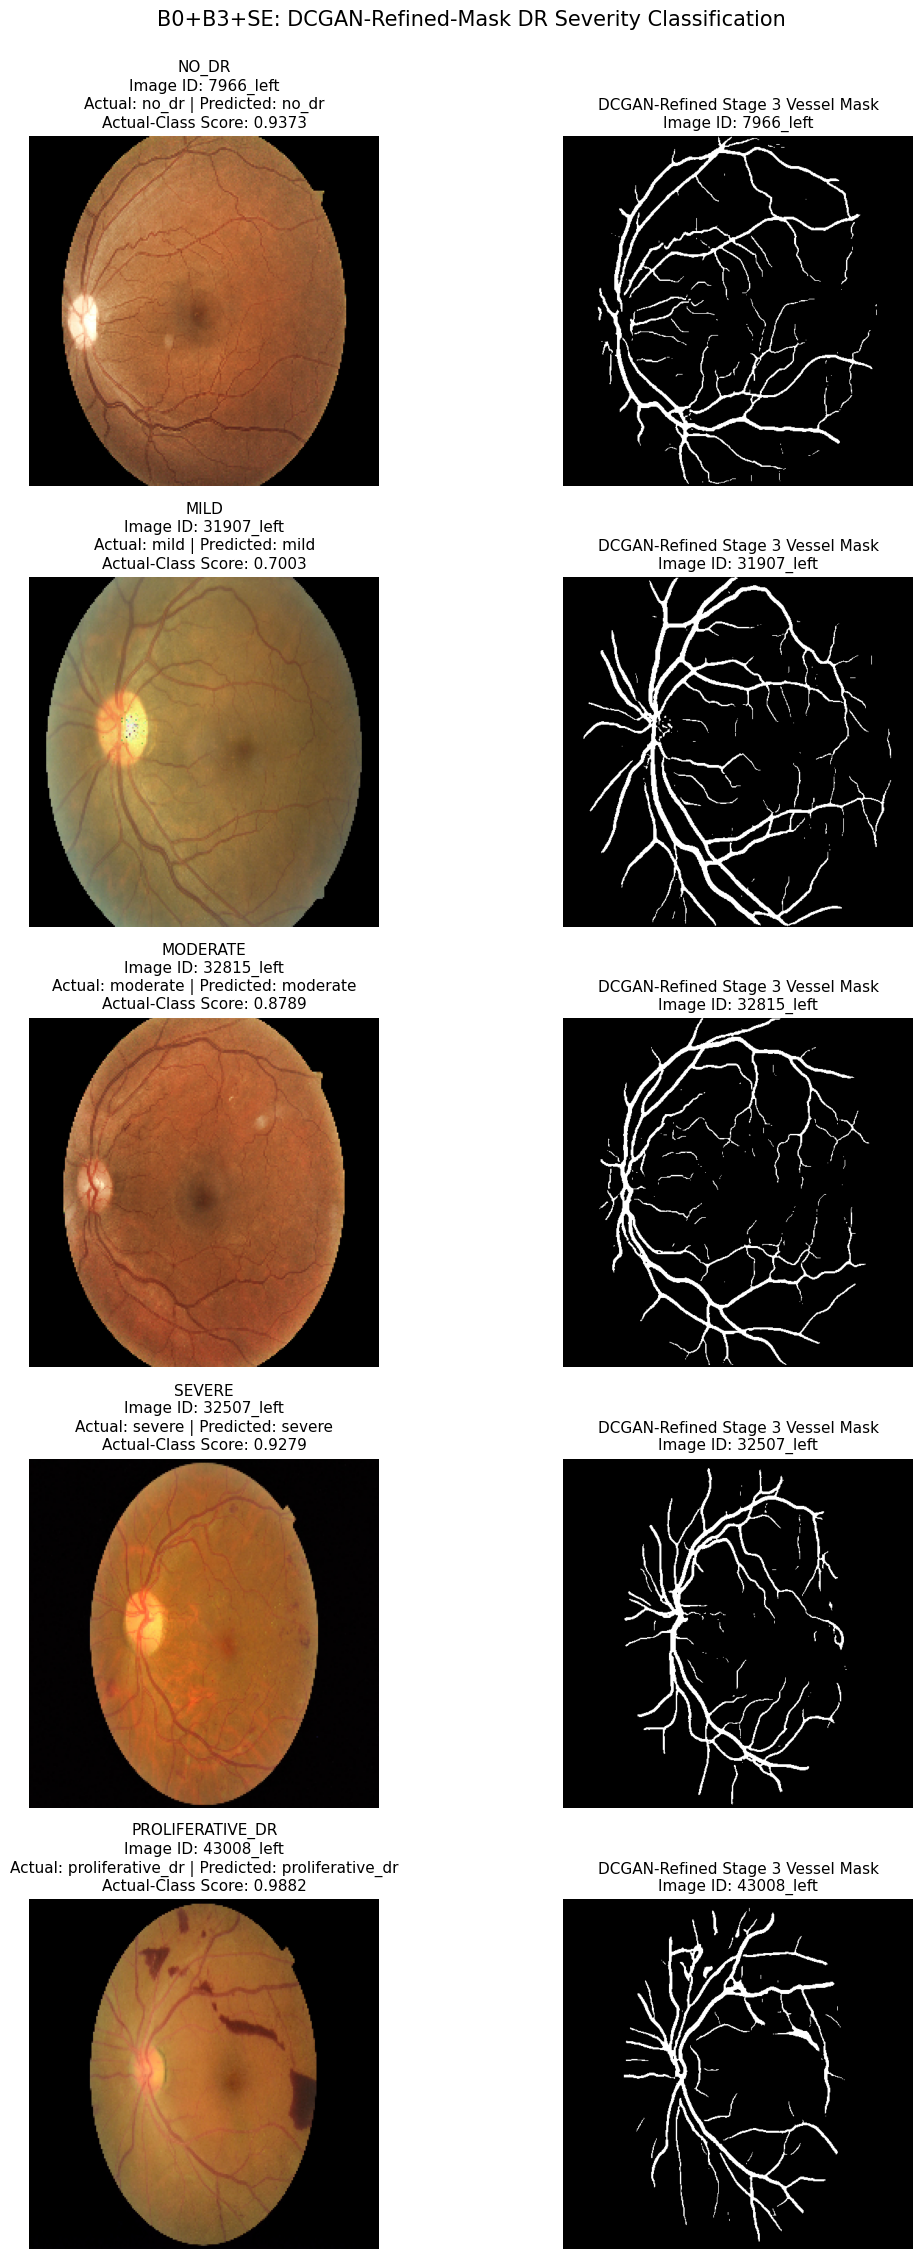


B0+B3+SE - DCGAN-REFINED SEVERITY SCORES
  Image_ID  Actual_Severity Predicted_Severity  Actual_Class_Score  No_DR_Score  Mild_Score  Moderate_Score  Severe_Score  Proliferative_DR_Score
 7966_left            no_dr              no_dr              0.9373       0.9373      0.0183          0.0046        0.0323                  0.0075
31907_left             mild               mild              0.7003       0.2495      0.7003          0.0126        0.0234                  0.0142
32815_left         moderate           moderate              0.8789       0.0826      0.0209          0.8789        0.0145                  0.0031
32507_left           severe             severe              0.9279       0.0004      0.0028          0.0404        0.9279                  0.0285
43008_left proliferative_dr   proliferative_dr              0.9882       0.0068      0.0036          0.0008        0.0006                  0.9882

Saved figure:
/content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/FINAL_FI

In [ ]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFilter



required = [
    "test_df",
    "s3_labels",
    "s3_preds",
    "s3_probs",
    "CLASS_NAMES",
    "OUT_DIR"
]

for name in required:
    if name not in globals():
        raise RuntimeError(
            f"{name} is missing. Run Cell 12 "
            "successfully before running this cell."
        )

if "BEST_MODEL" in globals():
    assert str(BEST_MODEL) in ("B3", "B4"), (
        "Expected B3 or B4 from validation selection."
    )

labels = np.asarray(s3_labels, dtype=int)
predictions = np.asarray(s3_preds, dtype=int)
probabilities = np.asarray(s3_probs, dtype=float)

assert len(test_df) == len(labels)
assert len(labels) == len(predictions)
assert len(labels) == len(probabilities)
assert probabilities.shape[1] == 5

assert np.array_equal(
    test_df["label"].to_numpy(dtype=int),
    labels
), "Test dataframe and predictions are not aligned."

RGB_COLUMN = "img_path"
MASK_COLUMN = "stage3_mask_path"

assert RGB_COLUMN in test_df.columns
assert MASK_COLUMN in test_df.columns

SAVE_DIR = os.path.join(
    OUT_DIR,
    "FINAL_FIVE_SEVERITY_IMAGES"
)

os.makedirs(SAVE_DIR, exist_ok=True)


print("Total test images:", len(labels))




def get_image_id(path):

    filename = os.path.basename(
        str(path)
    ).lower()

    match = re.search(
        r"(\d+_(?:left|right))",
        filename
    )

    return match.group(1) if match else None



def examine_image(rgb_path, mask_path):

    with Image.open(rgb_path) as im:
        rgb = im.convert("RGB").resize(
            (160, 160)
        )

    with Image.open(mask_path) as im:
        mask = im.convert("L").resize(
            (160, 160),
            Image.Resampling.NEAREST
        )

    rgb_arr = (
        np.asarray(rgb, dtype=np.float32) / 255.0
    )

    mask_arr = (
        np.asarray(mask, dtype=np.float32) / 255.0
    )

    retina = rgb_arr.max(axis=2) > 0.10

    if not np.any(retina):
        return None

    brightness = float(
        rgb_arr[retina].mean()
    )

    contrast = float(
        rgb_arr[retina].std()
    )

    retina_coverage = float(
        retina.mean()
    )

    vessel_coverage = float(
        (mask_arr > 0.5).mean()
    )



    green = Image.fromarray(
        np.uint8(rgb_arr[:, :, 1] * 255)
    )

    smooth = np.asarray(
        green.filter(
            ImageFilter.GaussianBlur(radius=6)
        ),
        dtype=np.float32
    )

    left_score = float(
        np.max(smooth[20:140, 15:65])
    )

    right_score = float(
        np.max(smooth[20:140, 95:145])
    )

    disc_position = (
        "left"
        if left_score > right_score
        else "right"
    )



    vessel_grid = []

    for r in range(4):
        for c in range(4):

            part = mask_arr[
                r * 40:(r + 1) * 40,
                c * 40:(c + 1) * 40
            ]

            vessel_grid.append(
                (part > 0.5).mean() > 0.003
            )

    vessel_spread = float(
        np.mean(vessel_grid)
    )

    brightness_score = max(
        0.0,
        1.0 - abs(brightness - 0.42) / 0.42
    )

    quality = (
        0.30 * brightness_score
        + 0.20 * min(contrast / 0.17, 1.0)
        + 0.20 * min(vessel_coverage / 0.025, 1.0)
        + 0.20 * vessel_spread
        + 0.10 * min(retina_coverage / 0.45, 1.0)
    )

    return {
        "Quality": float(quality),
        "Brightness": brightness,
        "Retina_Coverage": retina_coverage,
        "Vessel_Coverage": vessel_coverage,
        "Disc_Position": disc_position
    }




selected_images = []

for class_id, class_name in enumerate(CLASS_NAMES):

    possible_indices = []

    for i in range(len(test_df)):


        if int(labels[i]) != class_id:
            continue

        if int(predictions[i]) != class_id:
            continue

        row = test_df.iloc[i]

        rgb_path = str(row[RGB_COLUMN])
        mask_path = str(row[MASK_COLUMN])

        rgb_id = get_image_id(rgb_path)
        mask_id = get_image_id(mask_path)


        if rgb_id is None or rgb_id != mask_id:
            continue


        if not rgb_id.endswith("_left"):
            continue

        if not os.path.isfile(rgb_path):
            continue

        if not os.path.isfile(mask_path):
            continue


        normalized_path = mask_path.replace(
            "\\", "/"
        ).lower()

        if "/dr2015_stage3_dcgan_masks/" not in normalized_path:
            continue

        possible_indices.append(i)


    possible_indices.sort(
        key=lambda i: float(
            probabilities[i, class_id]
        ),
        reverse=True
    )

    candidates = []

    for i in possible_indices[:200]:

        row = test_df.iloc[i]

        rgb_path = str(row[RGB_COLUMN])
        mask_path = str(row[MASK_COLUMN])

        quality = examine_image(
            rgb_path,
            mask_path
        )

        if quality is None:
            continue


        if quality["Brightness"] < 0.17:
            continue

        if quality["Retina_Coverage"] < 0.25:
            continue


        if quality["Vessel_Coverage"] < 0.005:
            continue

        candidates.append({
            "Severity": class_name,
            "Image_ID": get_image_id(rgb_path),
            "RGB_Path": rgb_path,
            "Mask_Path": mask_path,
            "Actual": CLASS_NAMES[int(labels[i])],
            "Predicted": CLASS_NAMES[int(predictions[i])],
            "Score": float(
                probabilities[i, class_id]
            ),
            "Quality": quality["Quality"],
            "Disc_Position": quality["Disc_Position"],
            "Test_Index": i
        })

    if not candidates:

        raise RuntimeError(
            f"No suitable correctly classified "
            f"{class_name} image found with the "
            "current clarity and filename filters."
        )


    left_disc_candidates = [
        item for item in candidates
        if item["Disc_Position"] == "left"
    ]

    if left_disc_candidates:
        candidates = left_disc_candidates

    candidates.sort(
        key=lambda x: (
            x["Quality"],
            x["Score"]
        ),
        reverse=True
    )

    chosen = candidates[0]

    selected_images.append(chosen)

    print(
        f"{class_name:18s} | "
        f"ID: {chosen['Image_ID']:15s} | "
        f"Score: {chosen['Score']:.4f}"
    )




fig, axes = plt.subplots(
    5, 2,
    figsize=(12, 23)
)

for j, item in enumerate(selected_images):

    with Image.open(item["RGB_Path"]) as im:
        rgb_image = im.convert("RGB").copy()

    with Image.open(item["Mask_Path"]) as im:
        mask_image = im.convert("L").copy()

    axes[j, 0].imshow(rgb_image)

    axes[j, 0].set_title(
        f"{item['Severity'].upper()}\n"
        f"Image ID: {item['Image_ID']}\n"
        f"Actual: {item['Actual']} | "
        f"Predicted: {item['Predicted']}\n"
        f"Actual-Class Score: {item['Score']:.4f}",
        fontsize=11
    )

    axes[j, 0].axis("off")

    axes[j, 1].imshow(
        mask_image,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[j, 1].set_title(
        "DCGAN-Refined Stage 3 Vessel Mask\n"
        f"Image ID: {item['Image_ID']}",
        fontsize=11
    )

    axes[j, 1].axis("off")

    rgb_image.save(
        os.path.join(
            SAVE_DIR,
            f"{item['Image_ID']}_RGB.png"
        )
    )

    mask_image.save(
        os.path.join(
            SAVE_DIR,
            f"{item['Image_ID']}_dcgan_refined_mask.png"
        )
    )

plt.suptitle(
    f"B0+{BEST_MODEL}+SE: DCGAN-Refined-Mask DR Severity Classification",
    fontsize=15
)

plt.tight_layout(
    rect=[0, 0, 1, 0.98]
)

FIGURE_PATH = os.path.join(
    SAVE_DIR,
    f"B0_{BEST_MODEL}_SE_DCGAN_FIVE_SEVERITY_IMAGES.png"
)

plt.savefig(
    FIGURE_PATH,
    dpi=220,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)




score_rows = []

for item in selected_images:

    i = item["Test_Index"]

    score_rows.append({
        "Image_ID": item["Image_ID"],
        "Actual_Severity": item["Actual"],
        "Predicted_Severity": item["Predicted"],
        "Actual_Class_Score": item["Score"],
        "No_DR_Score": float(probabilities[i, 0]),
        "Mild_Score": float(probabilities[i, 1]),
        "Moderate_Score": float(probabilities[i, 2]),
        "Severe_Score": float(probabilities[i, 3]),
        "Proliferative_DR_Score": float(
            probabilities[i, 4]
        )
    })

scores_df = pd.DataFrame(score_rows)

print("\n" + "=" * 90)
print(f"B0+{BEST_MODEL}+SE - DCGAN-REFINED SEVERITY SCORES")
print("=" * 90)

print(
    scores_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

SCORES_PATH = os.path.join(
    SAVE_DIR,
    f"B0_{BEST_MODEL}_SE_DCGAN_FIVE_SEVERITY_SCORES.csv"
)

scores_df.to_csv(
    SCORES_PATH,
    index=False,
    float_format="%.6f"
)

print("\nSaved figure:")
print(FIGURE_PATH)

print("\nSaved severity-score CSV:")
print(SCORES_PATH)





Evaluating B0+B3+SE with refined Stage 3 masks...


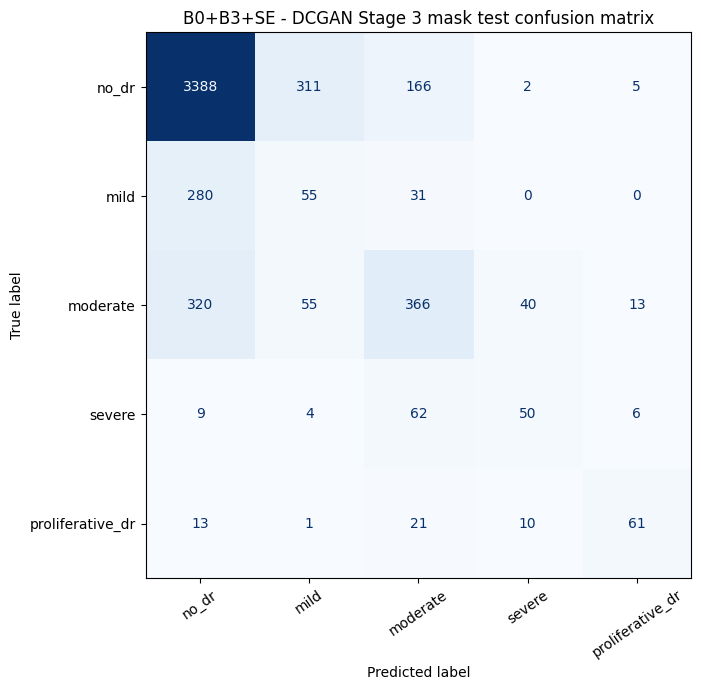

B0+B3+SE test accuracy=0.7440, Macro-F1=0.5150

Evaluating B0+B4+SE with refined Stage 3 masks...


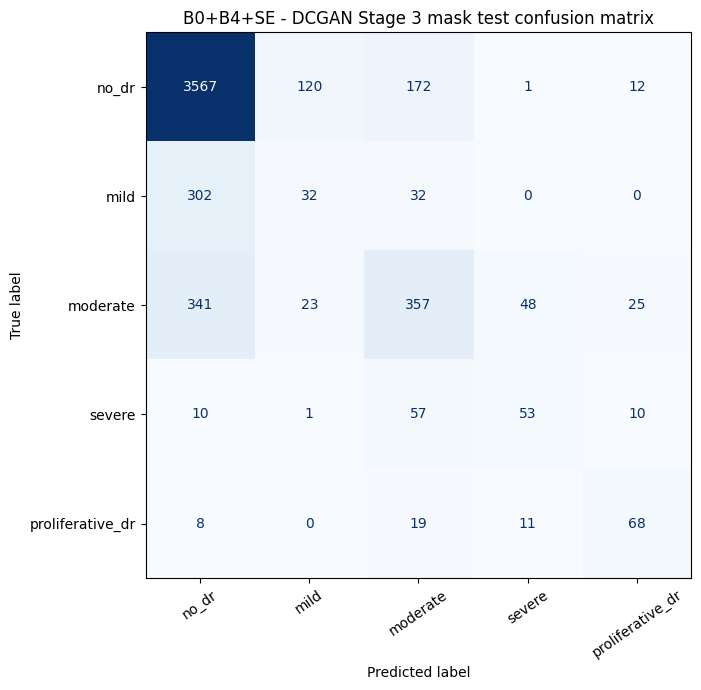

B0+B4+SE test accuracy=0.7738, Macro-F1=0.5095

BOTH MODELS - TEST METRICS (reporting only; validation selected the winner):
   model             mask_type  test_loss  test_accuracy  test_macro_f1  test_weighted_f1  test_macro_auroc
B0+B3+SE DCGAN-refined Stage 3     1.0698         0.7440         0.5150            0.7415            0.8044
B0+B4+SE DCGAN-refined Stage 3     1.0006         0.7738         0.5095            0.7538            0.8283
Saved detailed test outputs: /content/drive/MyDrive/DR_Project/DR2015_DCGAN_B0_B3_B4_SE/both_architectures_test


In [ ]:
# CELL 15 - HELD-OUT TEST REPORT FOR BOTH PRE-SPECIFIED B3 AND B4 MODELS
# Do NOT use these test scores to choose the architecture; the winner above
# was selected exclusively using validation Macro-F1.
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path
from torch.utils.data import DataLoader

DUAL_TEST_DIR=Path(OUT_DIR)/'both_architectures_test'
DUAL_TEST_DIR.mkdir(parents=True,exist_ok=True)
summary_rows=[]

for short_name, timm_name in {'B3':'tf_efficientnet_b3.ns_jft_in1k',
                              'B4':'tf_efficientnet_b4.ns_jft_in1k'}.items():
    checkpoint_path=Path(OUT_DIR)/f'stage3_{short_name}_best.pth'
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f'Complete Cell 10 training first: {checkpoint_path}')
    print(f'\nEvaluating B0+{short_name}+SE with refined Stage 3 masks...')
    batch_size=BATCH_BY_MODEL[short_name]
    loader=DataLoader(stage3_test_ds,batch_size=batch_size,shuffle=False,
                      num_workers=min(4,STAGE3_NUM_WORKERS),pin_memory=PIN_MEMORY)
    model=Stage3EfficientNetB0BxSE(num_classes,LOCAL_STAGE1_W,timm_name,
                                    mask_pretrained=False).to(device)
    model.load_state_dict(torch.load(checkpoint_path,map_location=device,weights_only=False),strict=True)
    model.eval()
    measured=evaluate_with_loss(model,loader)
    y_true=measured['labels']; y_pred=measured['preds']; probs=measured['probs']
    if len(y_true)!=len(test_df) or not np.array_equal(test_df['label'].to_numpy(dtype=int),y_true):
        raise RuntimeError('Test labels or image ordering do not match the official split.')
    summary_rows.append({'model':f'B0+{short_name}+SE',
                         'mask_type':'DCGAN-refined Stage 3',
                         'test_loss':measured['loss'],
                         'test_accuracy':measured['accuracy'],
                         'test_macro_f1':measured['macro_f1'],
                         'test_weighted_f1':measured['weighted_f1'],
                         'test_macro_auroc':measured['macro_auc']})
    per_image=test_df[['basename','label','class_name','stage3_mask_path']].copy()
    per_image['predicted_label']=y_pred
    per_image['predicted_name']=[CLASS_NAMES[int(x)] for x in y_pred]
    per_image['predicted_confidence']=probs.max(axis=1)
    per_image['actual_class_confidence']=probs[np.arange(len(y_true)),y_true]
    for i,c in enumerate(CLASS_NAMES): per_image[f'prob_{c}']=probs[:,i]
    per_image.to_csv(DUAL_TEST_DIR/f'{short_name}_test_predictions.csv',index=False)
    report=classification_report(y_true,y_pred,labels=list(range(num_classes)),
                                 target_names=CLASS_NAMES,output_dict=True,zero_division=0)
    pd.DataFrame(report).T.to_csv(DUAL_TEST_DIR/f'{short_name}_classification_report.csv')
    cm=confusion_matrix(y_true,y_pred,labels=list(range(num_classes)))
    pd.DataFrame(cm,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(
        DUAL_TEST_DIR/f'{short_name}_confusion_matrix.csv')
    fig,ax=plt.subplots(figsize=(8,7))
    ConfusionMatrixDisplay(cm,display_labels=CLASS_NAMES).plot(ax=ax,xticks_rotation=35,cmap='Blues',colorbar=False)
    ax.set_title(f'B0+{short_name}+SE - DCGAN Stage 3 mask test confusion matrix')
    plt.tight_layout()
    fig.savefig(DUAL_TEST_DIR/f'{short_name}_test_confusion_matrix.png',dpi=220)
    plt.show();plt.close(fig)
    print(f'B0+{short_name}+SE test accuracy={measured["accuracy"]:.4f}, Macro-F1={measured["macro_f1"]:.4f}')
    del model,loader,measured
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

dual_test=pd.DataFrame(summary_rows)
dual_test.to_csv(DUAL_TEST_DIR/'B3_B4_DCgan_test_comparison.csv',index=False)
print('\nBOTH MODELS - TEST METRICS (reporting only; validation selected the winner):')
print(dual_test.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('Saved detailed test outputs:',DUAL_TEST_DIR)
